<a href="https://colab.research.google.com/github/danielsolomoncods/ds-GitHub/blob/main/Copy_of_Solomon_SuperKart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem Statement
# Business Context
A sales forecast predicts future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits, which include improved decision-making about the future and the reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establishes benchmarks that can be used to assess trends in the future.
## Objective
SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm, not just to build a predictive model based on historical sales data but also to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Dictionary
The data contains the different attributes of the various products and stores.
* Product_Id: Unique identifier of each product, each identifier having two letters at the beginning, followed by a number
* Product_Weight: Weight of each product
* Product_Sugar_Content: Sugar content of each product, like low sugar, regular, and no sugar
* Product_Allocated_Area: Ratio of the allocated display area of each * product to the total display area of all the products in a store
* Product_Type: Broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
*Product_MRP: Maximum retail price of each product
* Store_Id: Unique identifier of each store
* Store_Establishment_Year: Year in which the store was established
* Store_Size: Size of the store, depending on sq. feet, like high, medium, and low
* Store_Location_City_Type: Type of city in which the store is located, like Tier 1, Tier 2, and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than that of its Tier 2 and Tier 3 counterparts
* Store_Type: Type of store depending on the products that are being sold there, like Departmental Store, Supermarket Type 1, Supermarket Type 2, and Food Mart
* Product_Store_Sales_Total: Total revenue generated by the sale of that particular product in that particular store

# Installing and Importing the Necessary Libraries

In [ ]:
# ---------------------------------------------------------
# Installing Required Libraries
# This section installs all the specific library versions
# needed for the project, ensuring compatibility and
# reproducibility across environments. These include:
# - Data manipulation (NumPy, Pandas)
# - Machine learning (scikit-learn, XGBoost)
# - Visualization (Matplotlib, Seaborn)
# - Model saving (joblib)
# - API requests and Hugging Face integration
# The first command installs quietly (-q), while the second
# installs with full output for debugging if needed.
# ---------------------------------------------------------

# Install the required libraries with the specified versions
!pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 joblib==1.4.2 xgboost==2.1.4 requests==2.32.3 huggingface_hub==0.30.1 -q
# Install the required libraries with the specified versions
!pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 joblib==1.4.2 xgboost==2.1.4 requests==2.32.3 huggingface_hub==0.30.1


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 301.8/301.8 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.9/64.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 481.2/481.2 kB 9.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.32.3 which is incompatible.
google-adk 1.29.0 requires requests<3.0.0,>=2.32.4, but you have requests 2.32.3 which is incompatible.
gradio 5.50.0 requires huggingface-hub<2.0,>=0.33.5, but you have huggingface-hub 0.30.1 which is incompatible.
diffusers 0.37.1 requires huggingface-hub<2.0,>=0.34.0, but you have huggingface-hub 0.30.1 which is incompatible.
transformers 5.0.0 requires huggingface-hub<2.0,>=1.3.0, but you have huggingf

In [ ]:
# ---------------------------------------------------------
# Importing Required Libraries
# This section loads all essential libraries used throughout
# the project, including:
# - Warning suppression for cleaner output
# - Data handling (NumPy, Pandas)
# - Data visualization (Matplotlib, Seaborn)
# - Model training utilities (train-test split, pipelines,
#   preprocessing, hyperparameter tuning)
# - Ensemble and tree-based regression models
# - Evaluation metrics for model performance
# - Model serialization (joblib)
# - OS operations and API requests
# - Hugging Face authentication for uploading files
# These imports ensure the environment is fully prepared for
# data analysis, model building, tuning, and deployment.
# ---------------------------------------------------------

import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# For splitting the dataset
from sklearn.model_selection import train_test_split

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# Libraries different ensemble classifiers
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
)
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor

# Libraries to get different metric scores
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

# To create the pipeline
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,Pipeline

# To tune different models and standardize
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder

# To serialize the model
import joblib

# os related functionalities
import os

# API request
import requests

# for hugging face space authentication to upload files
from huggingface_hub import login, HfApi

## Loading the Dataset

In [ ]:
# ---------------------------------------------------------
# Loading Dataset from Google Drive
# This section performs the following:
# - Mounts Google Drive so Colab can access stored files
# - Loads the SuperKart.csv dataset into a pandas DataFrame
# - Creates a safety backup copy of the dataset to preserve
#   the original data before any cleaning or transformations
# - Verifies that the backup was created successfully
# ---------------------------------------------------------

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Load the dataset
import pandas as pd
file_path = "/content/drive/My Drive/SuperKart/SuperKart.csv"

df = pd.read_csv(file_path)
df.head()

# Make a safety copy of the original dataset
df_backup = df.copy()

# Optional: verify the copy
print("Backup created. Shape:", df_backup.shape)



Mounted at /content/drive
Backup created. Shape: (8763, 12)


# Data Overview
Loading the data

In [ ]:
# ---------------------------------------------------------
#  Data Overview
# This section provides a quick understanding of the dataset:
# - Shows the number of rows and columns (dataset shape)
# - Lists all column names
# - Displays data types for each feature
# - Shows the first few rows to preview the data
# - Provides summary statistics for numerical columns
# - Checks for missing values in each column
# This helps assess structure, quality, and potential issues early.
# ---------------------------------------------------------

# Shape of the dataset
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types of each column
print("\nData Types:")
print(df.dtypes)

# First 5 rows
print("\nFirst 5 Rows:")
display(df.head())

# Summary statistics for numeric columns
print("\nSummary Statistics:")
display(df.describe())

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (8763, 12)

Column Names:
['Product_Id', 'Product_Weight', 'Product_Sugar_Content', 'Product_Allocated_Area', 'Product_Type', 'Product_MRP', 'Store_Id', 'Store_Establishment_Year', 'Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Product_Store_Sales_Total']

Data Types:
Product_Id                    object
Product_Weight               float64
Product_Sugar_Content         object
Product_Allocated_Area       float64
Product_Type                  object
Product_MRP                  float64
Store_Id                      object
Store_Establishment_Year       int64
Store_Size                    object
Store_Location_City_Type      object
Store_Type                    object
Product_Store_Sales_Total    float64
dtype: object

First 5 Rows:


,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36



Summary Statistics:


,Product_Weight,Product_Allocated_Area,Product_MRP,Store_Establishment_Year,Product_Store_Sales_Total
count,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000
mean,12.653792,0.068786,147.032539,2002.032751,3464.003640
std,2.217320,0.048204,30.694110,8.388381,1065.630494
min,4.000000,0.004000,31.000000,1987.000000,33.000000
25%,11.150000,0.031000,126.160000,1998.000000,2761.715000
50%,12.660000,0.056000,146.740000,2009.000000,3452.340000
75%,14.180000,0.096000,167.585000,2009.000000,4145.165000
max,22.000000,0.298000,266.000000,2009.000000,8000.000000



Missing Values:
Product_Id                   0
Product_Weight               0
Product_Sugar_Content        0
Product_Allocated_Area       0
Product_Type                 0
Product_MRP                  0
Store_Id                     0
Store_Establishment_Year     0
Store_Size                   0
Store_Location_City_Type     0
Store_Type                   0
Product_Store_Sales_Total    0
dtype: int64


##Exploratory Data Analysis (EDA)


Numerical Columns: ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Establishment_Year', 'Product_Store_Sales_Total']
Categorical Columns: ['Product_Id', 'Product_Sugar_Content', 'Product_Type', 'Store_Id', 'Store_Size', 'Store_Location_City_Type', 'Store_Type']


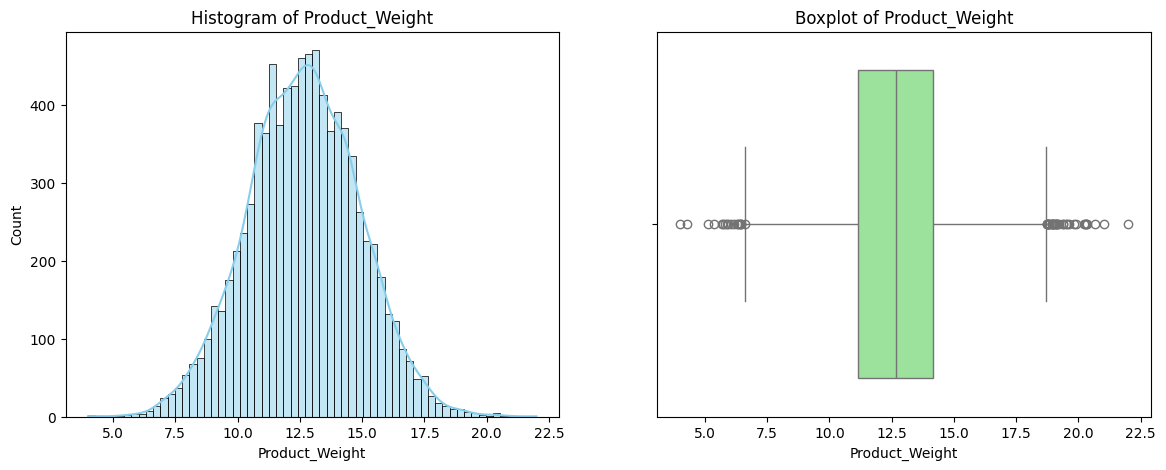

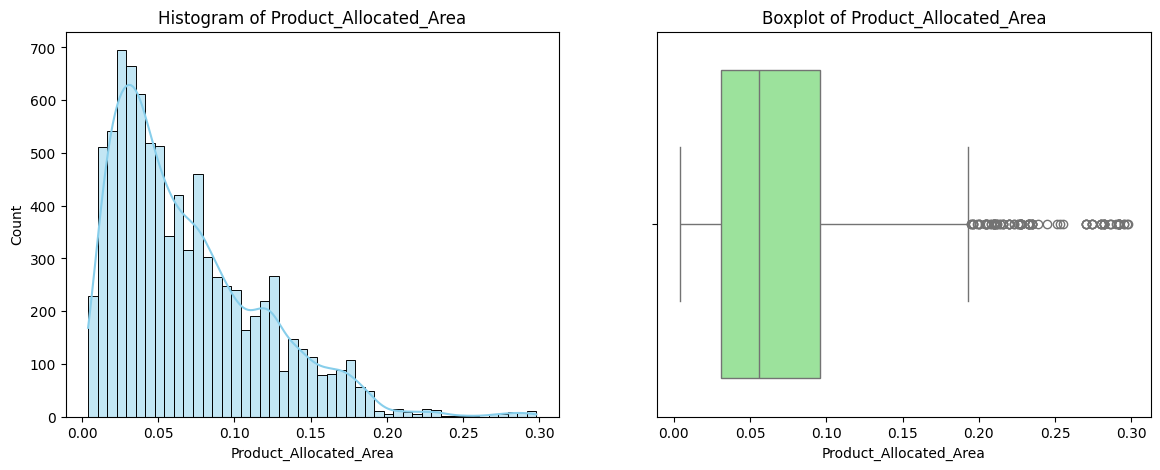

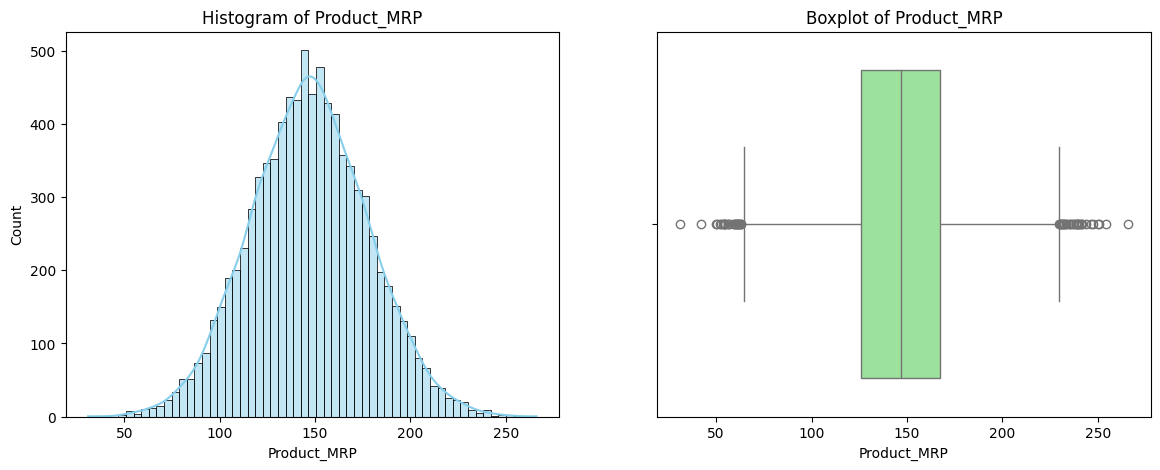

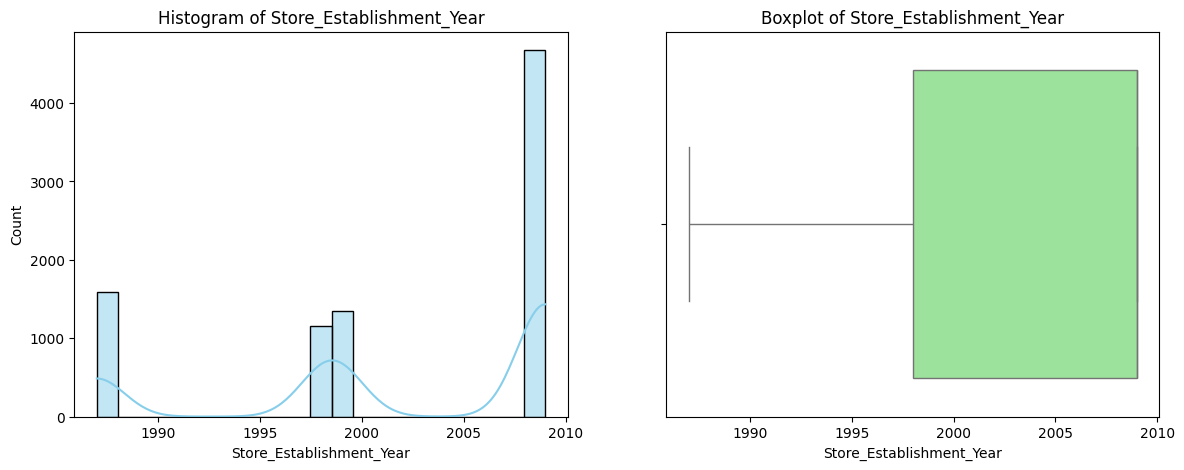

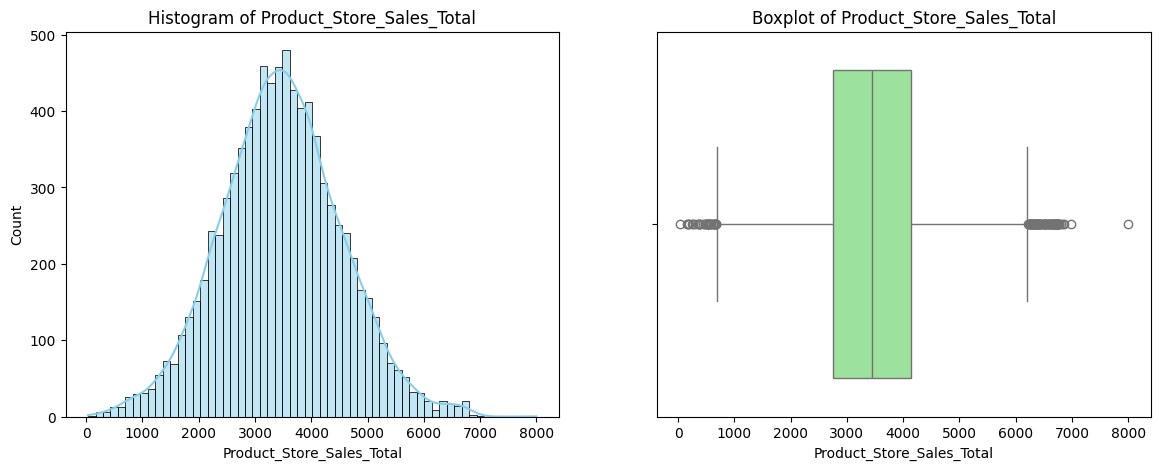

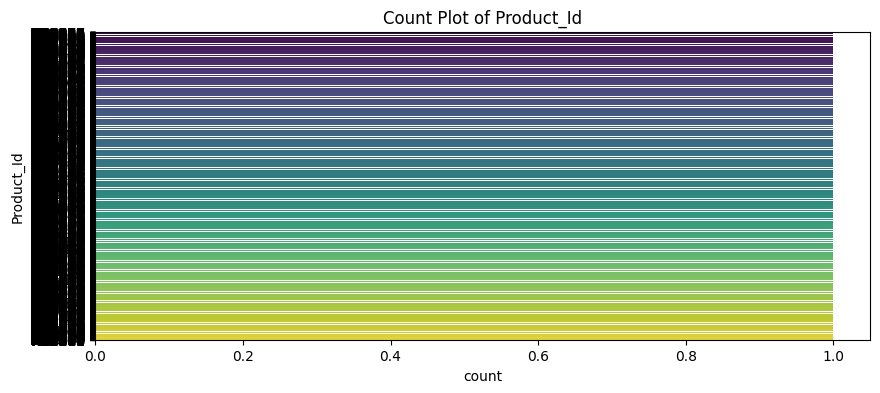

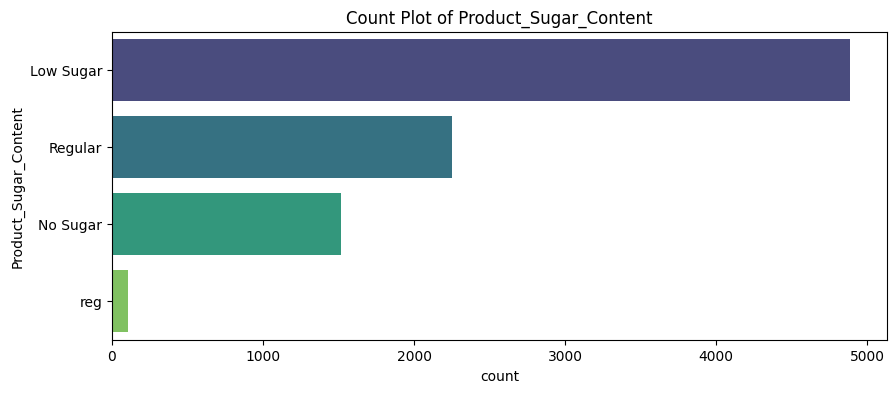

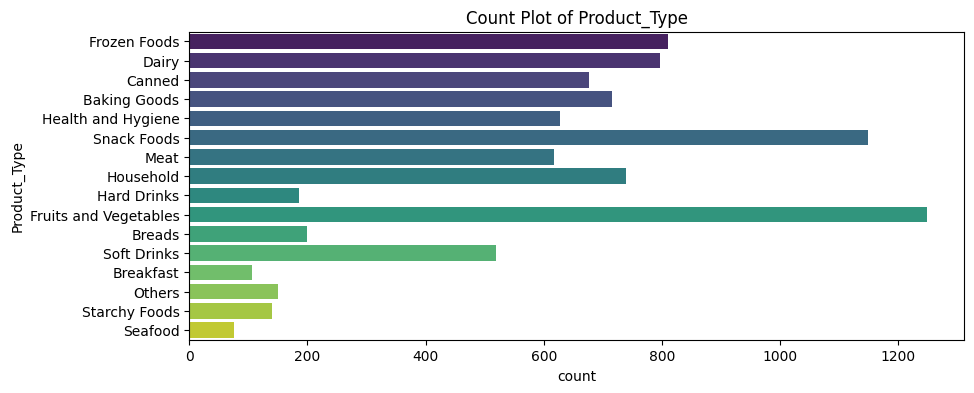

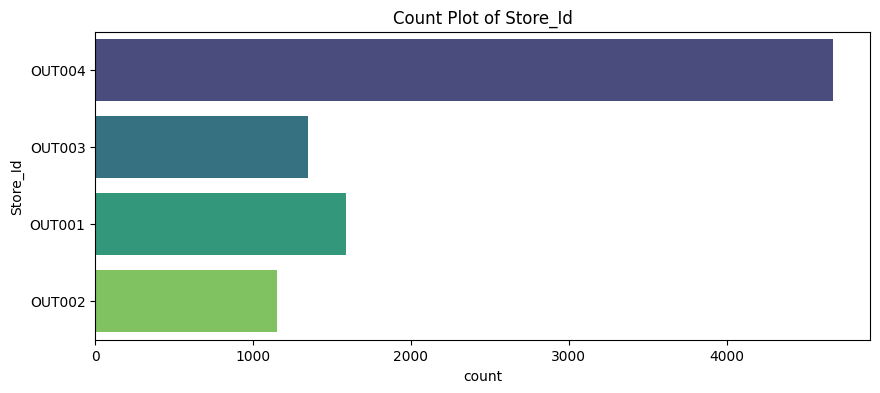

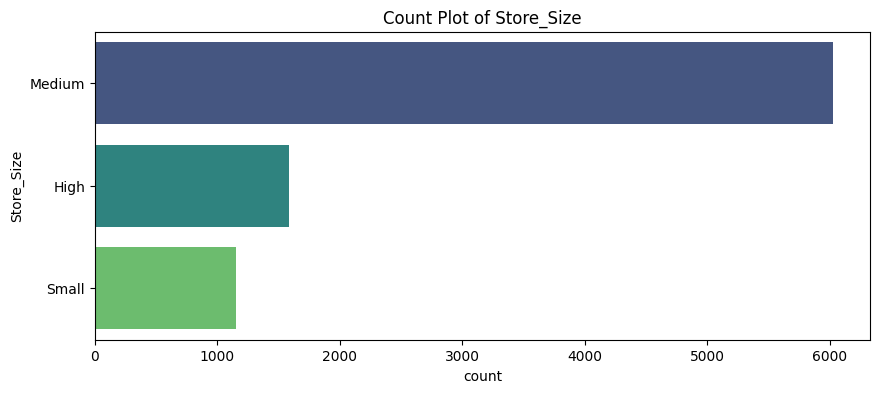

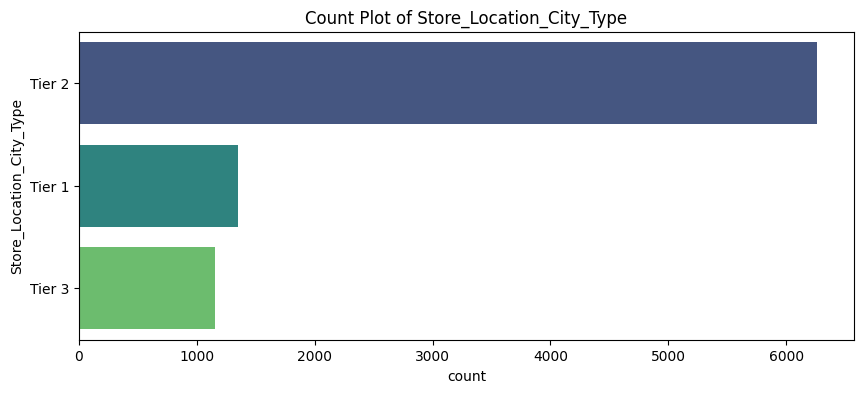

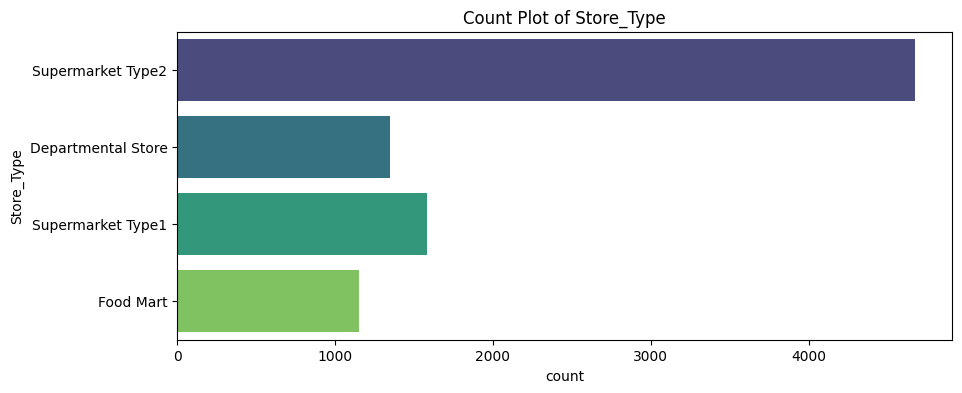

In [ ]:
# ---------------------------------------------------------
# Univariate Analysis
# This section analyzes each feature individually to understand:
# - The distribution of numerical variables (using histograms & boxplots)
# - The presence of outliers in numerical features
# - The frequency counts of categories in categorical features
# This helps identify data patterns, skewness, and potential issues early.
# ---------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns

# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns

print("Numerical Columns:", list(num_cols))
print("Categorical Columns:", list(cat_cols))

# -----------------------------
# Numerical Features
# -----------------------------
for col in num_cols:
    plt.figure(figsize=(14, 5))

    # Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(df[col], kde=True, color='skyblue')
    plt.title(f"Histogram of {col}")

    # Boxplot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[col], color='lightgreen')
    plt.title(f"Boxplot of {col}")

    plt.show()

# -----------------------------
# Categorical Features
# -----------------------------
for col in cat_cols:
    plt.figure(figsize=(10, 4))
    sns.countplot(y=df[col], palette='viridis')
    plt.title(f"Count Plot of {col}")
    plt.show()


Numerical Columns: ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Establishment_Year', 'Product_Store_Sales_Total']
Categorical Columns: ['Product_Id', 'Product_Sugar_Content', 'Product_Type', 'Store_Id', 'Store_Size', 'Store_Location_City_Type', 'Store_Type']

--- Numerical vs Numerical  ---


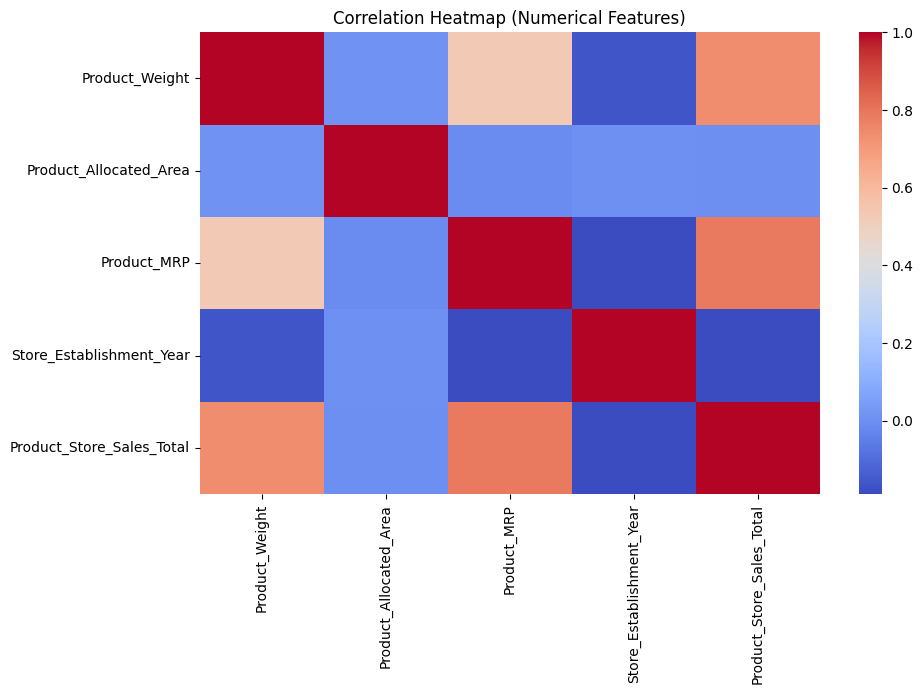


Top correlated numerical pairs: Product_MRP     Product_Store_Sales_Total    0.787989
Product_Weight  Product_Store_Sales_Total    0.737955
                Product_MRP                  0.532716
dtype: float64


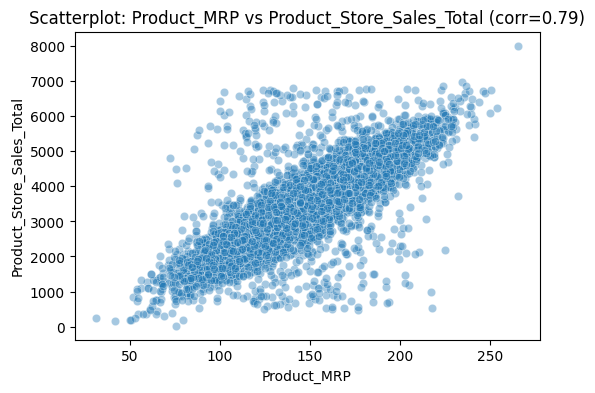

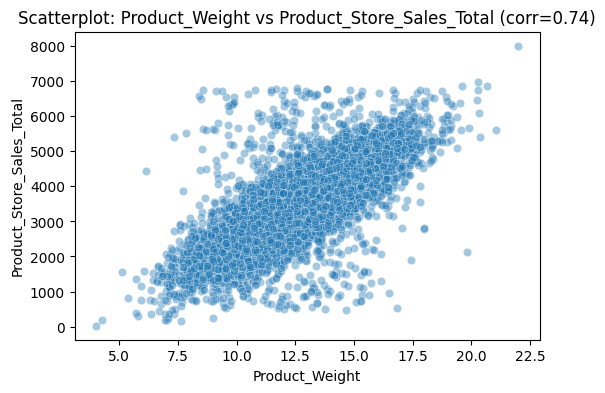

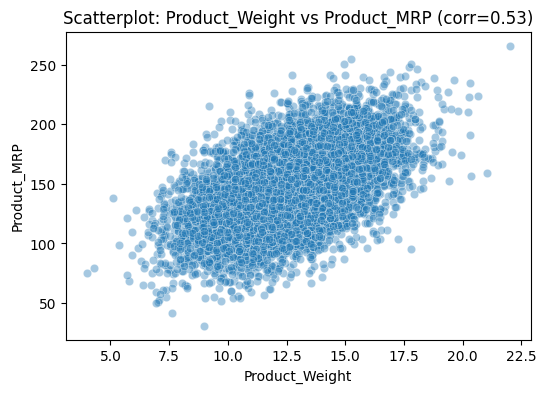


--- Numerical vs Categorical (Optimized) ---
Skipping Product_Id (too many categories: 8763)


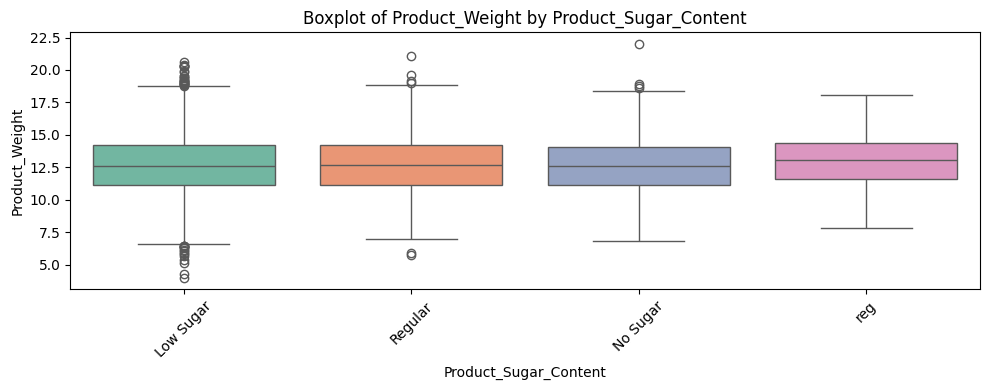

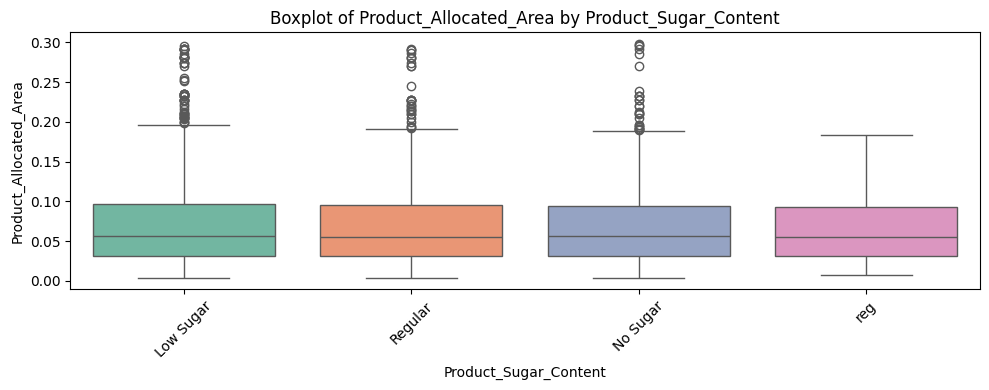

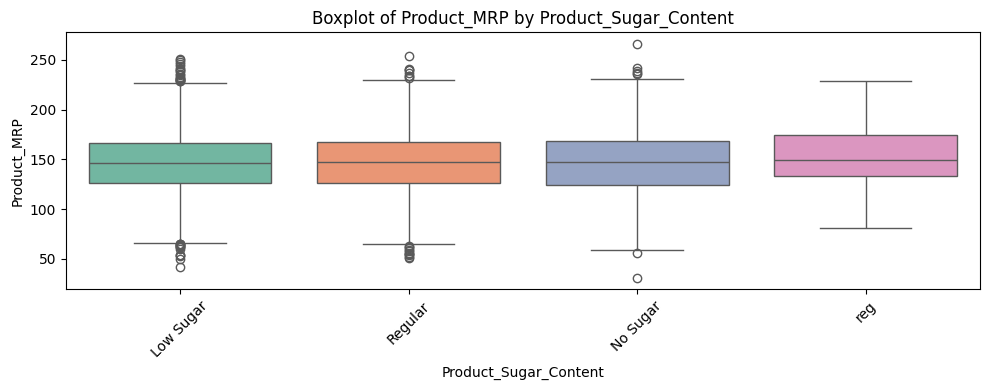

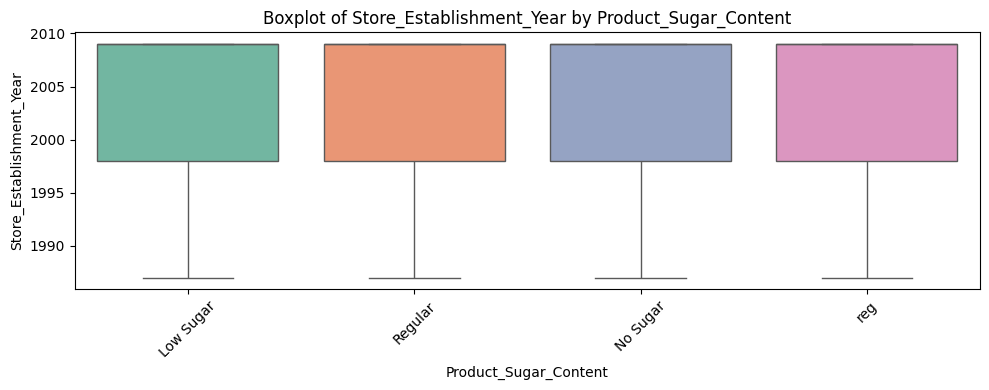

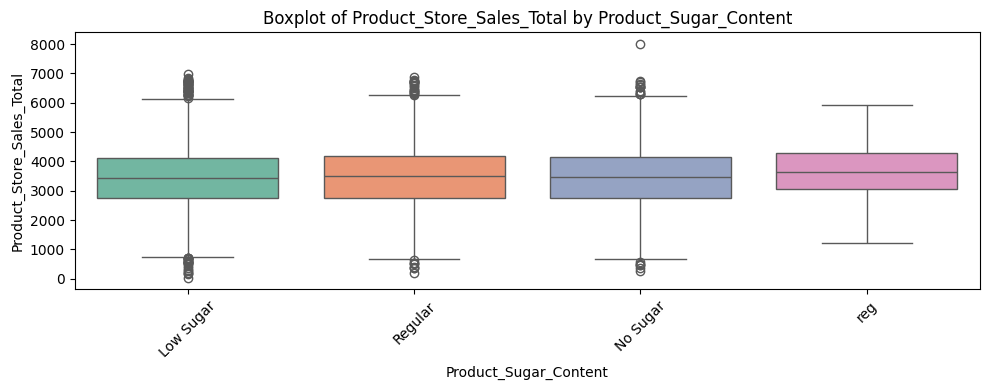

Skipping Product_Type (too many categories: 16)


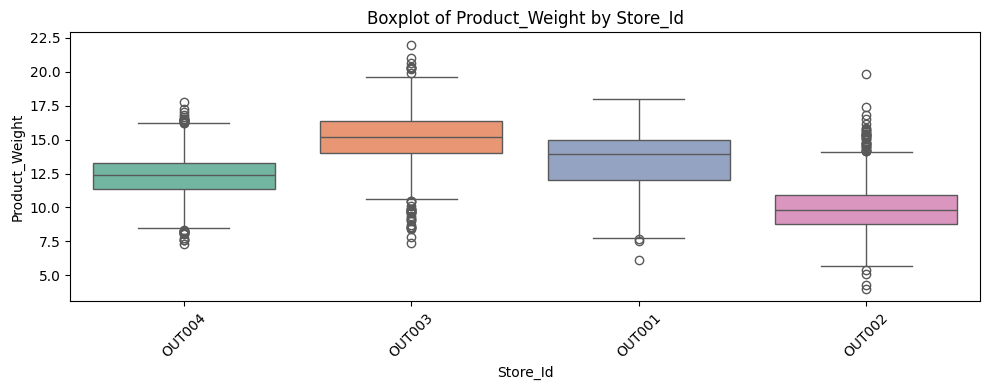

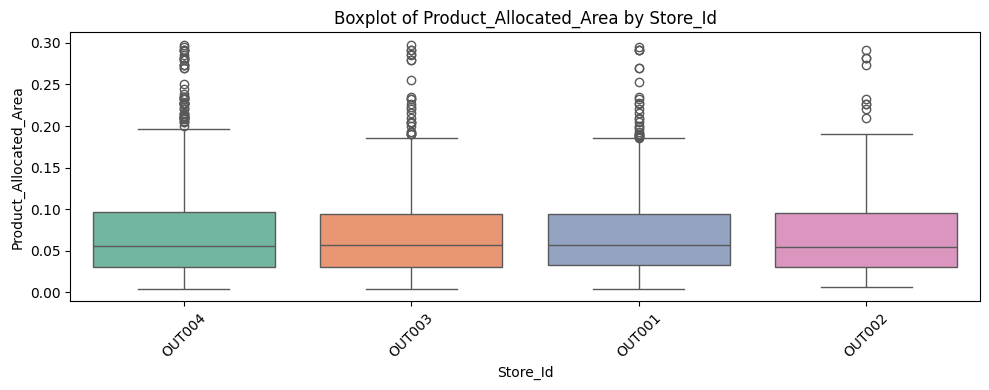

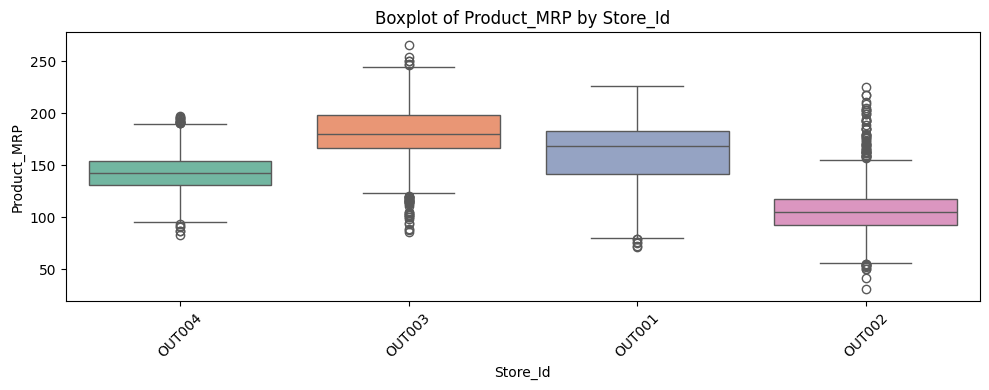

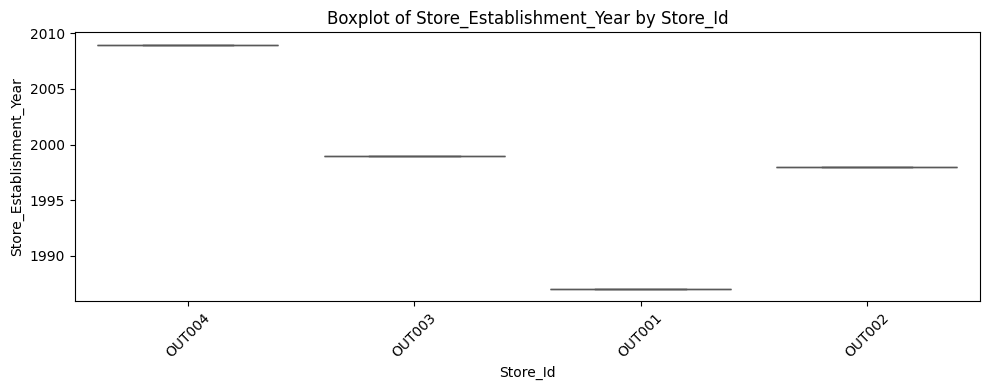

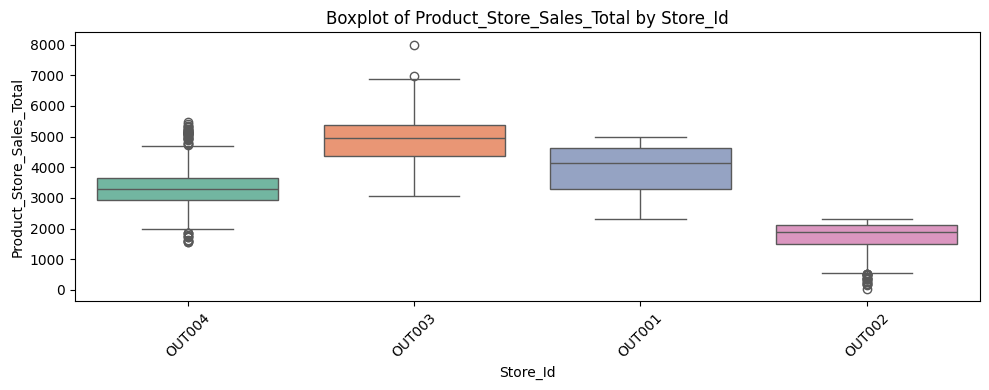

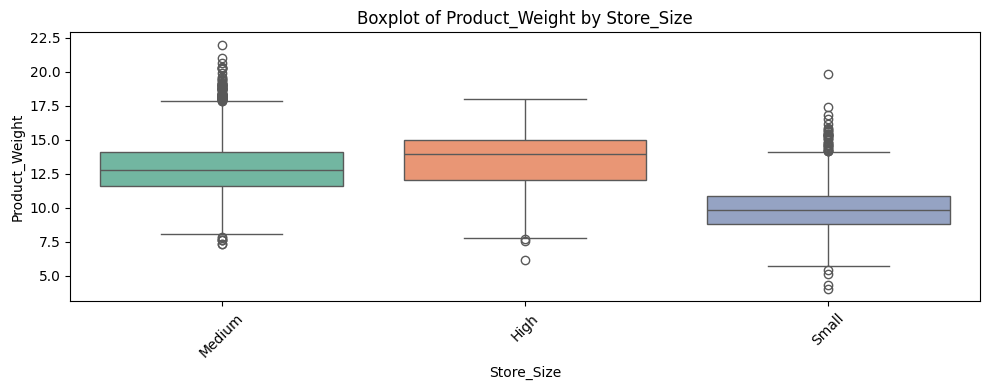

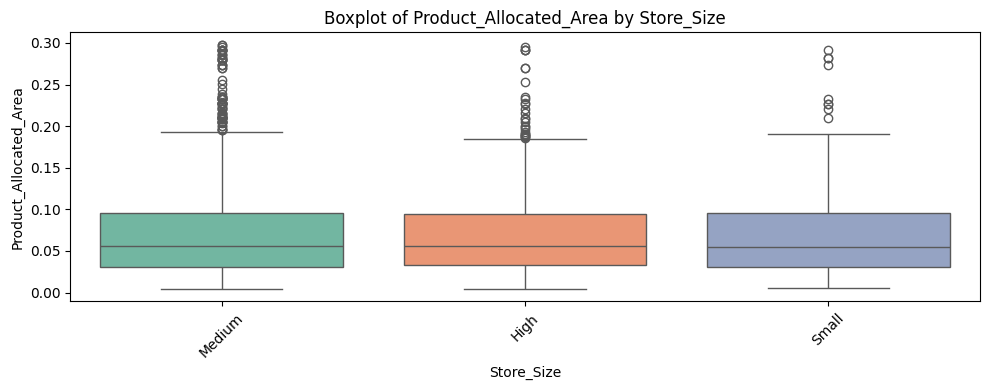

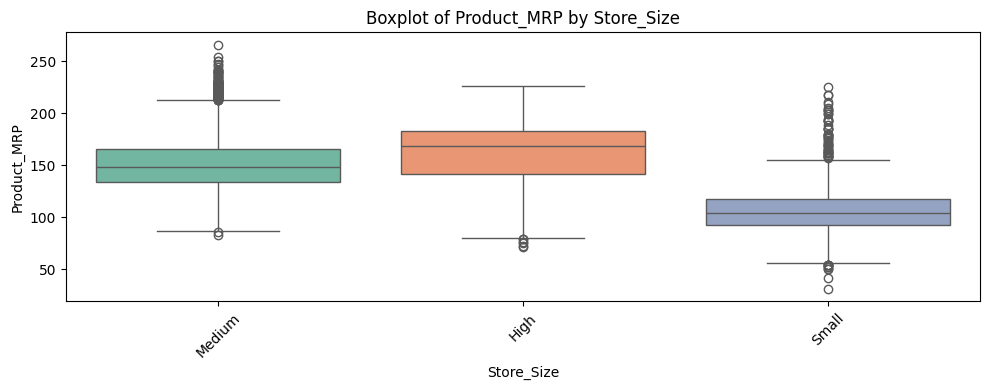

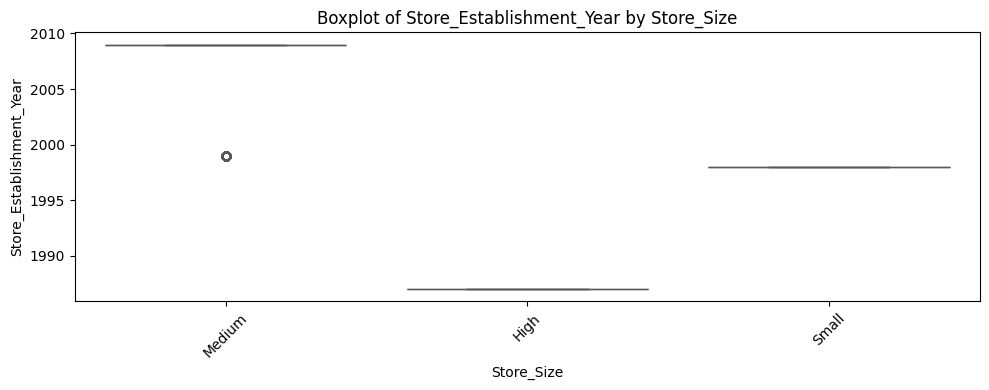

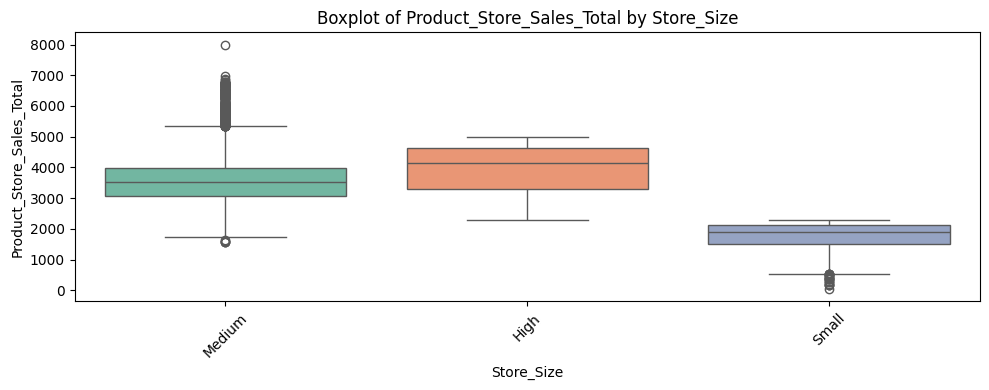

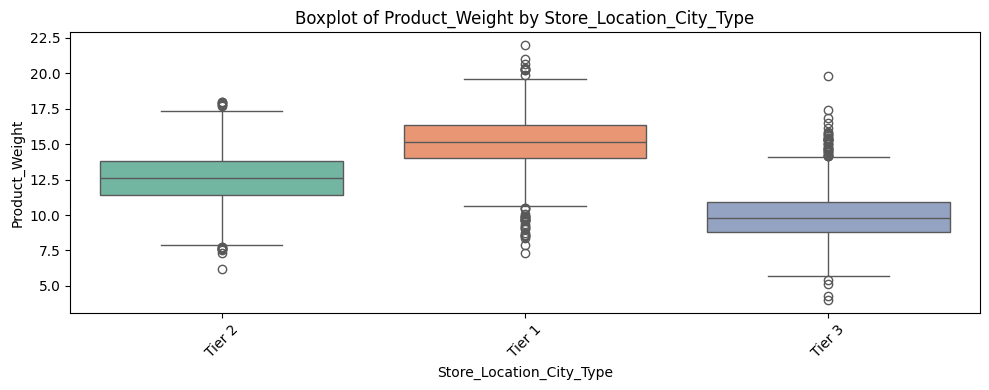

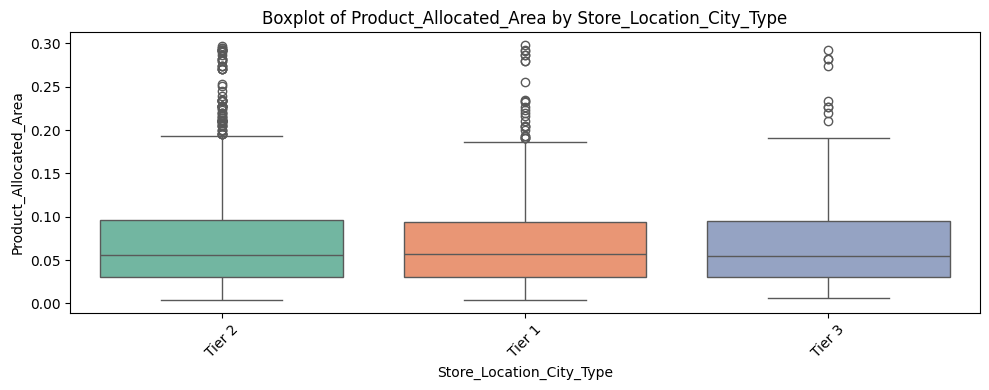

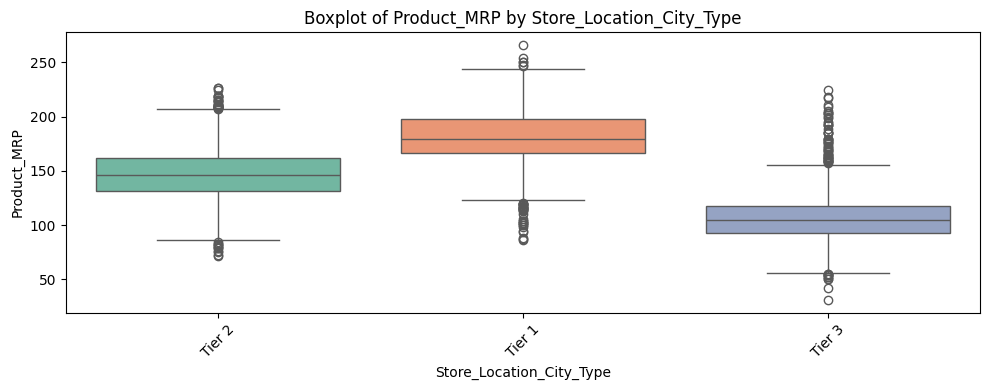

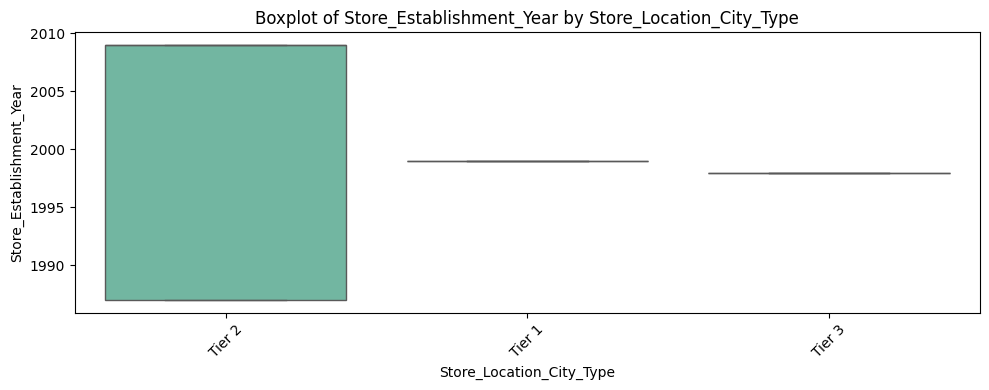

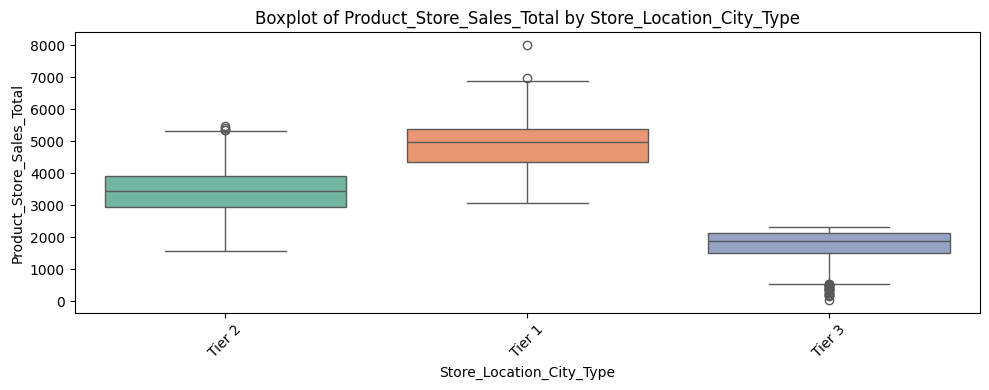

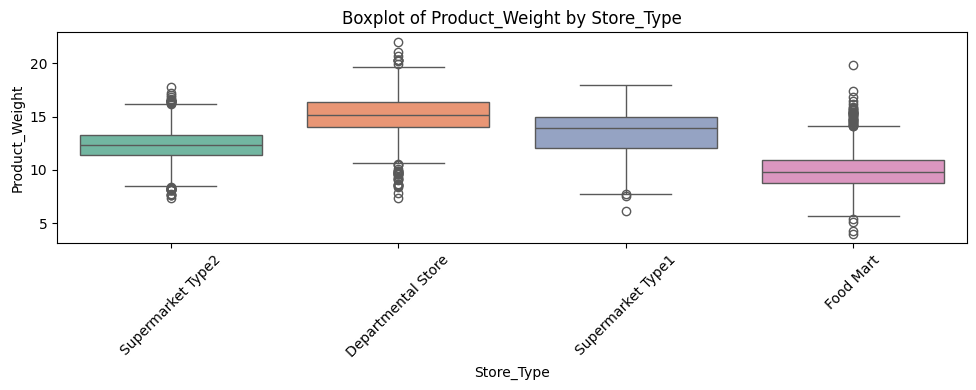

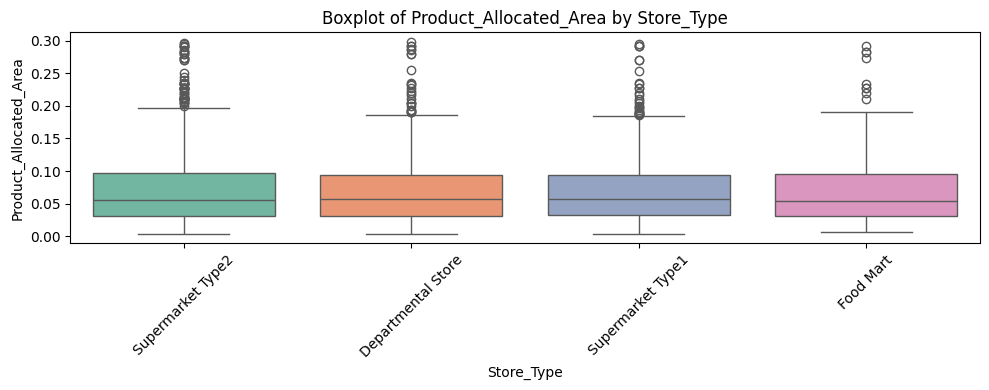

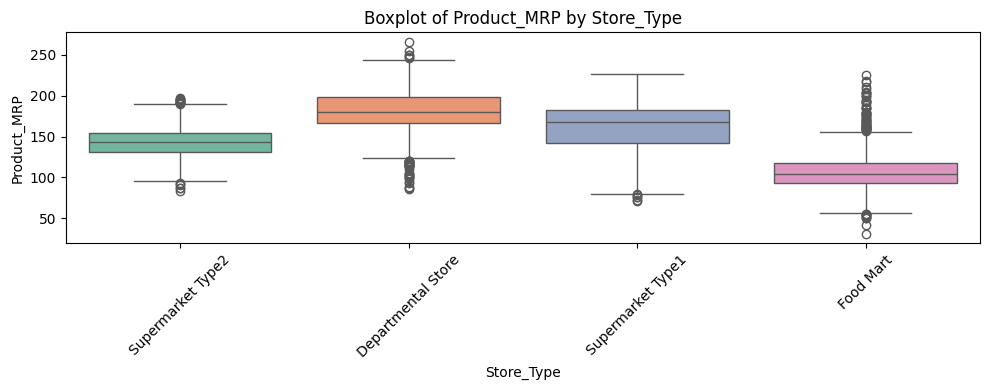

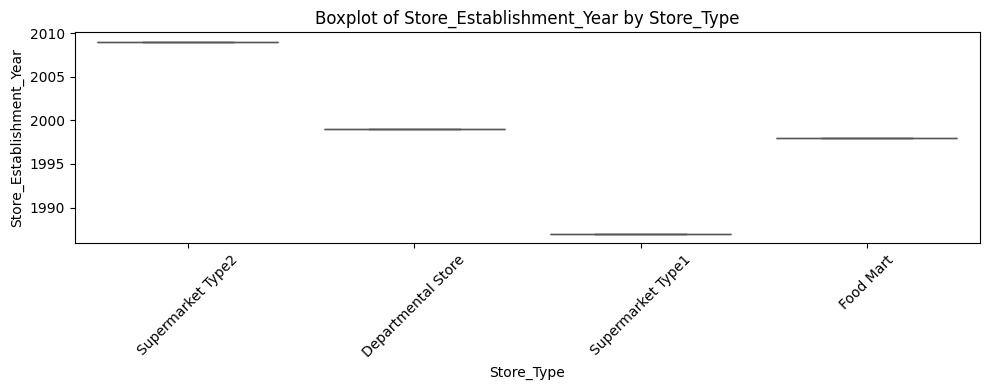

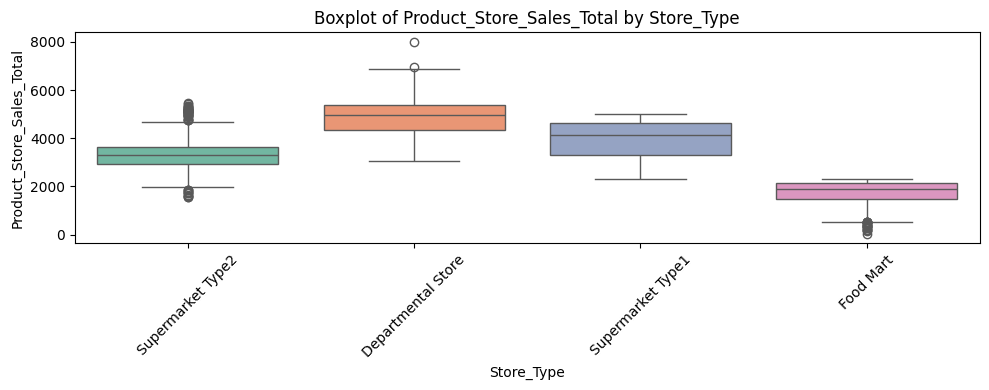


--- Categorical vs Categorical (Optimized) ---
Skipping Product_Id vs Product_Sugar_Content (too many categories)
Skipping Product_Id vs Product_Type (too many categories)
Skipping Product_Id vs Store_Id (too many categories)
Skipping Product_Id vs Store_Size (too many categories)
Skipping Product_Id vs Store_Location_City_Type (too many categories)
Skipping Product_Id vs Store_Type (too many categories)
Skipping Product_Sugar_Content vs Product_Type (too many categories)


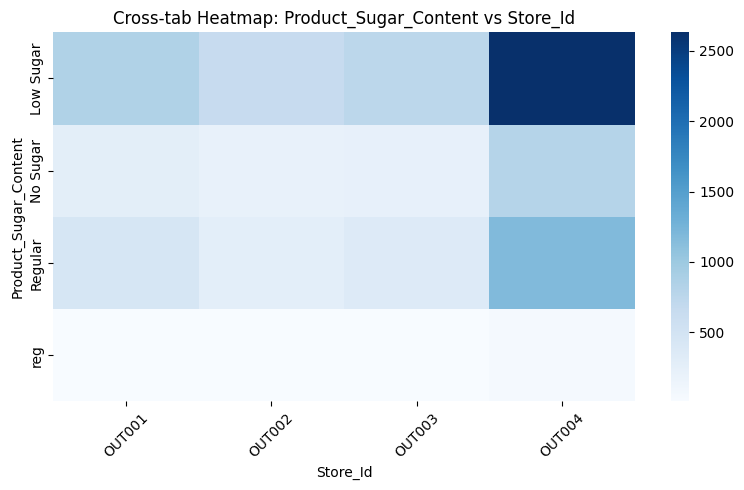

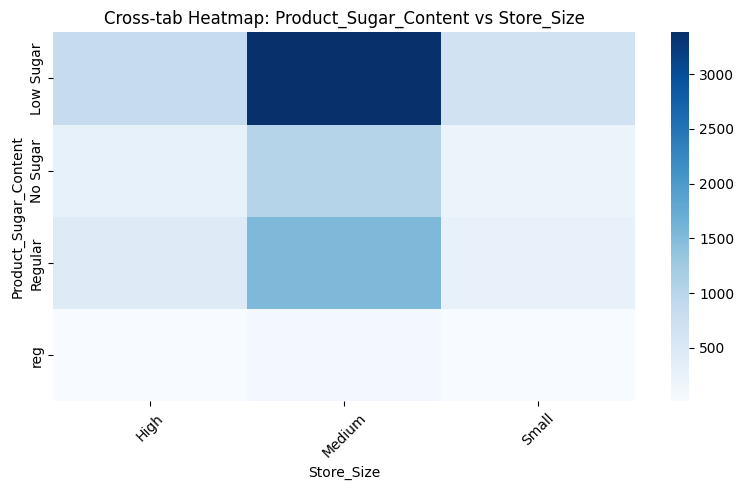

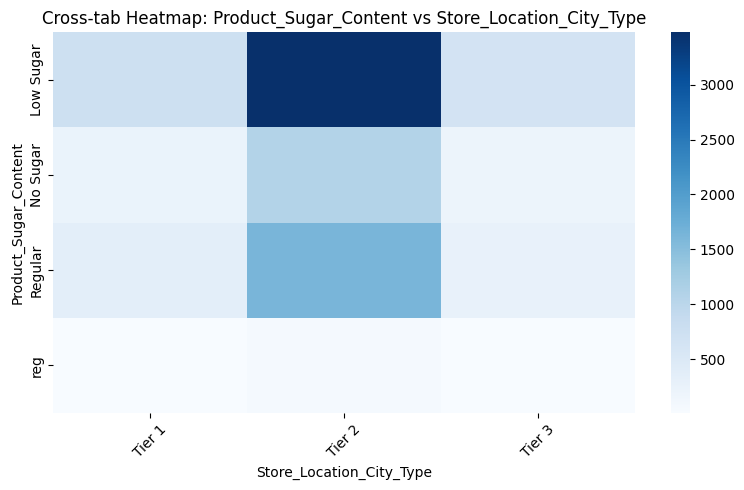

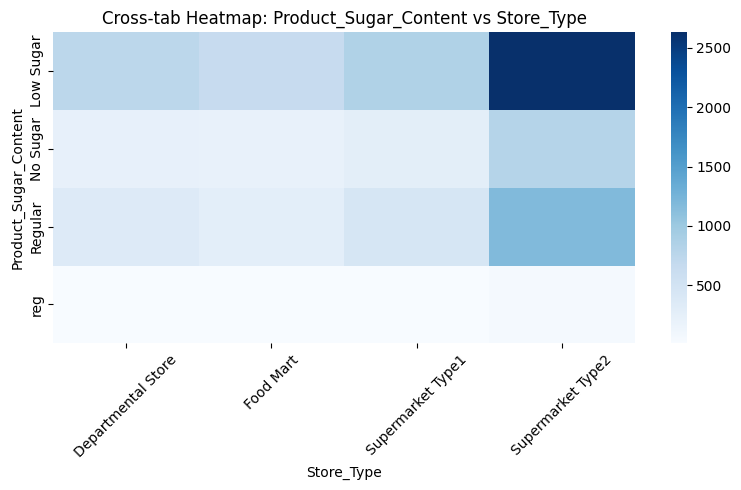

Skipping Product_Type vs Store_Id (too many categories)
Skipping Product_Type vs Store_Size (too many categories)
Skipping Product_Type vs Store_Location_City_Type (too many categories)
Skipping Product_Type vs Store_Type (too many categories)


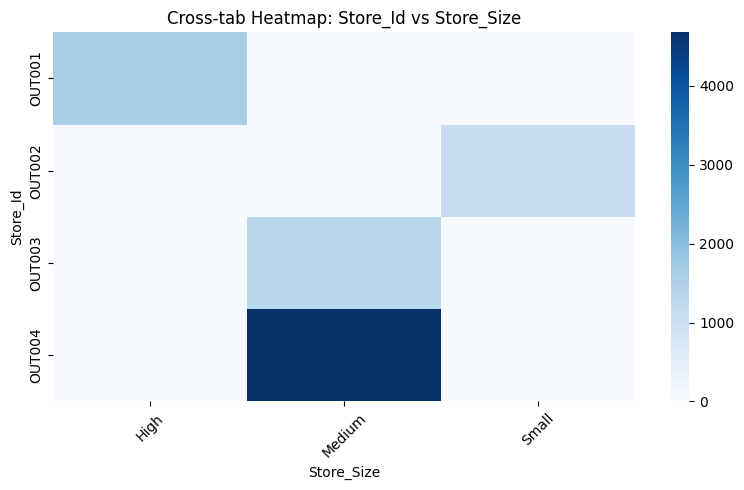

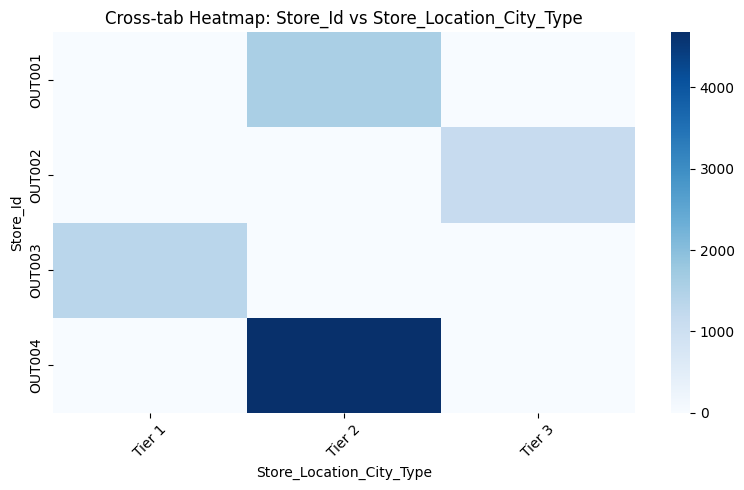

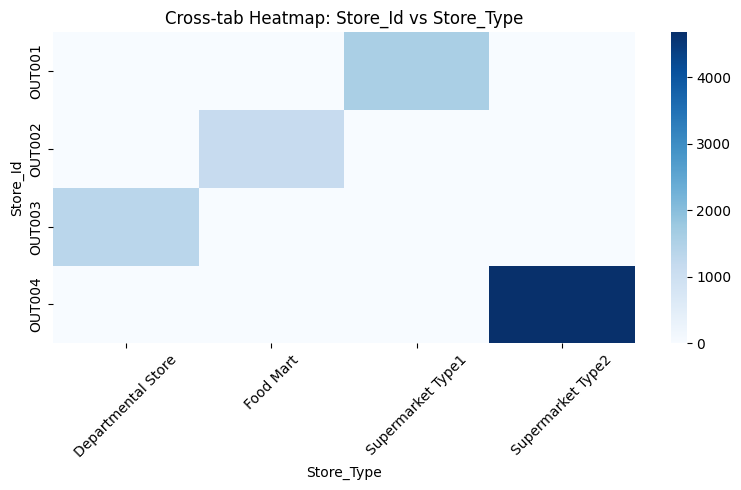

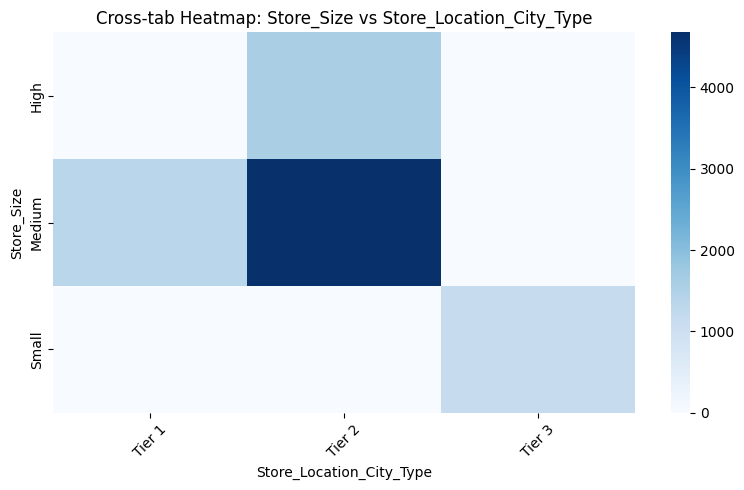

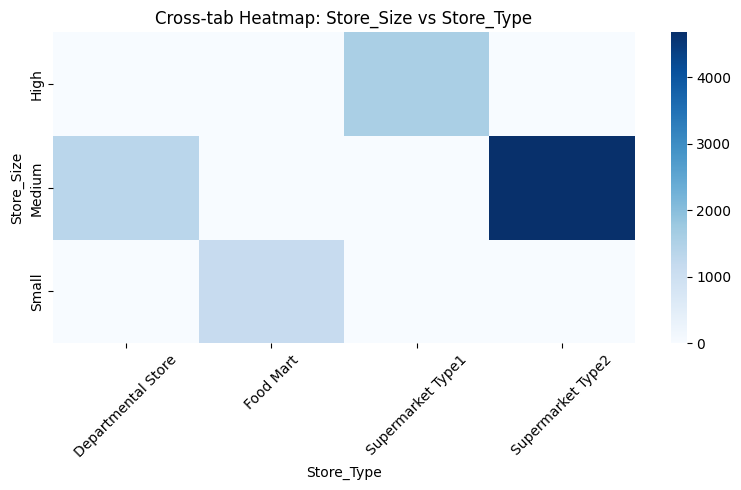

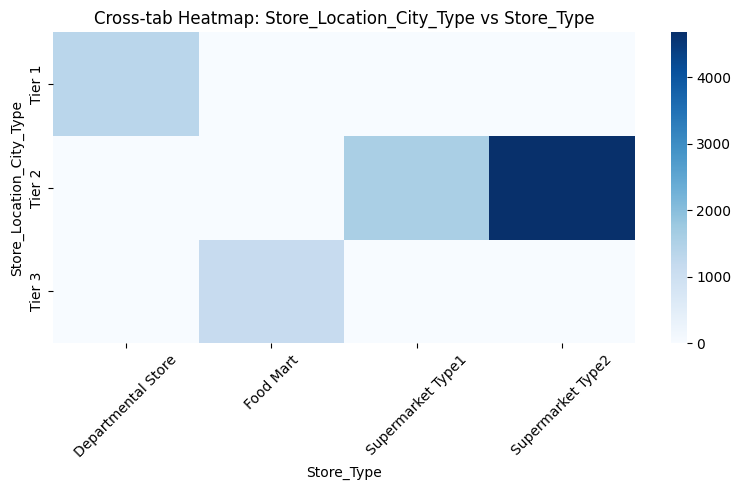

In [ ]:
# ---------------------------------------------------------
# Bivariate Analysis
# ---------------------------------------------------------

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Identify column types
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns

print("Numerical Columns:", list(num_cols))
print("Categorical Columns:", list(cat_cols))

# ---------------------------------------------------------
#  Numerical vs Numerical
# ---------------------------------------------------------
print("\n--- Numerical vs Numerical  ---")

# Correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df[num_cols].corr(), annot=False, cmap='coolwarm')
plt.title("Correlation Heatmap (Numerical Features)")
plt.show()

#  scatterplots for TOP correlated pairs only
corr_matrix = df[num_cols].corr().abs()
top_pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
    .head(3)
)

print("\nTop correlated numerical pairs:", top_pairs)

for (col1, col2), val in top_pairs.items():
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=df[col1], y=df[col2], alpha=0.4)
    plt.title(f"Scatterplot: {col1} vs {col2} (corr={val:.2f})")
    plt.show()

# ---------------------------------------------------------
# Numerical vs Categorical
# ---------------------------------------------------------
print("\n--- Numerical vs Categorical (Optimized) ---")

# Limit categories to avoid slow plots
MAX_CATS = 8

for cat in cat_cols:
    if df[cat].nunique() > MAX_CATS:
        print(f"Skipping {cat} (too many categories: {df[cat].nunique()})")
        continue

    for num in num_cols:
        plt.figure(figsize=(10, 4))
        sns.boxplot(x=df[cat], y=df[num], palette='Set2')
        plt.title(f"Boxplot of {num} by {cat}")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

# ---------------------------------------------------------
#  Categorical vs Categorical
# ---------------------------------------------------------
print("\n--- Categorical vs Categorical (Optimized) ---")

for i in range(len(cat_cols)):
    for j in range(i + 1, len(cat_cols)):
        cat1, cat2 = cat_cols[i], cat_cols[j]

        # Skip if too many categories
        if df[cat1].nunique() > MAX_CATS or df[cat2].nunique() > MAX_CATS:
            print(f"Skipping {cat1} vs {cat2} (too many categories)")
            continue

        ctab = pd.crosstab(df[cat1], df[cat2])

        plt.figure(figsize=(8, 5))
        sns.heatmap(ctab, annot=False, cmap="Blues")
        plt.title(f"Cross-tab Heatmap: {cat1} vs {cat2}")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()


## Data Preprocessing

In [ ]:
# ---------------------------------------------------------
#  Data Preprocessing Pipeline (SuperKart Sales Forecasting)
# ---------------------------------------------------------
# This section prepares the SuperKart dataset for machine learning by:
# - Validating and selecting the correct target variable
# - Identifying numerical and categorical feature types
# - Handling missing values using median (numeric) and mode (categorical)
# - Removing duplicate records to ensure data integrity
# - Splitting the dataset into features (X) and target (y)
# - Building a preprocessing pipeline that:
#       • Scales numerical features using StandardScaler
#       • Encodes categorical features using OneHotEncoder
# - Performing a train–test split to create unbiased evaluation sets
#
# These preprocessing steps ensure the dataset is clean, consistent,
# and fully compatible with downstream regression models used for
# SuperKart sales forecasting and deployment workflows.
# ---------------------------------------------------------


import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline

# -----------------------------
# 0. Set the correct target column
# -----------------------------
target = "Product_Store_Sales_Total"   # <-- Correct target

# Validate target column
if target not in df.columns:
    raise ValueError(
        f" Target column '{target}' not found. Available columns: {df.columns.tolist()}"
    )

# Identify column types
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Remove target from num_cols if present
if target in num_cols:
    num_cols.remove(target)

print("Numerical Columns:", num_cols)
print("Categorical Columns:", cat_cols)

# -----------------------------
# 1. Handle missing values
# -----------------------------
print("\nMissing Values Before Handling:")
print(df.isnull().sum())

df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])

print("\nMissing Values After Handling:")
print(df.isnull().sum())

# -----------------------------
# 2. Remove duplicates
# -----------------------------
print("\nDuplicates Before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates After:", df.duplicated().sum())

# -----------------------------
# 3. Split features & target
# -----------------------------
X = df.drop(columns=[target])
y = df[target]

# -----------------------------
# 4. Preprocessing Pipeline
# -----------------------------
preprocessor = make_column_transformer(
    (StandardScaler(), num_cols),
    (OneHotEncoder(handle_unknown='ignore'), cat_cols)
)

# -----------------------------
# 5. Train-test split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nData Preprocessing Completed Successfully!")
print("Training Set Shape:", X_train.shape)
print("Testing Set Shape:", X_test.shape)


Numerical Columns: ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Establishment_Year']
Categorical Columns: ['Product_Id', 'Product_Sugar_Content', 'Product_Type', 'Store_Id', 'Store_Size', 'Store_Location_City_Type', 'Store_Type']

Missing Values Before Handling:
Product_Id                   0
Product_Weight               0
Product_Sugar_Content        0
Product_Allocated_Area       0
Product_Type                 0
Product_MRP                  0
Store_Id                     0
Store_Establishment_Year     0
Store_Size                   0
Store_Location_City_Type     0
Store_Type                   0
Product_Store_Sales_Total    0
dtype: int64

Missing Values After Handling:
Product_Id                   0
Product_Weight               0
Product_Sugar_Content        0
Product_Allocated_Area       0
Product_Type                 0
Product_MRP                  0
Store_Id                     0
Store_Establishment_Year     0
Store_Size                   0
Store_Location_City

## Model Building
## Define functions for Model Evaluation

In [ ]:
# ---------------------------------------------------------
# Model Building & Evaluation (Using Custom Metrics)
# This section builds TWO regression models selected
# from the allowed list and evaluates them using a custom
# performance framework tailored for SuperKart’s sales
# forecasting needs.
#
# Metrics used:
# - RMSE: Measures prediction error in revenue units
# - MAE: Average absolute error
# - MAPE: Business-friendly % error
# - R² & Adjusted R²: Goodness of fit and model generalization
#
# ---------------------------------------------------------

import numpy as np
import pandas as pd
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

# ---------------------------------------------------------
# Adjusted R-squared Function
# ---------------------------------------------------------
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# ---------------------------------------------------------
# Unified Regression Performance Function
# ---------------------------------------------------------
def model_performance_regression(model, predictors, target):
    """
    Computes RMSE, MAE, MAPE, R², and Adjusted R² for a regression model.
    """
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)
    adjr2 = adj_r2_score(predictors, target, pred)
    rmse = np.sqrt(mean_squared_error(target, pred))
    mae = mean_absolute_error(target, pred)
    mape = mean_absolute_percentage_error(target, pred)

    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "MAPE": mape,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
        },
        index=[0],
    )

    return df_perf


# ---------------------------------------------------------
# Build & Evaluate TWO Models
# ---------------------------------------------------------
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    BaggingRegressor
)
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

def build_and_evaluate_selected_models(preprocessor, X_train, X_test, y_train, y_test):
    """
    Builds pipelines for ANY TWO selected regression models and evaluates them.
    """

    # -----------------------------------------------------
    # SELECT MODEL/S
    # -----------------------------------------------------
    selected_models = {
        "Random Forest": RandomForestRegressor(random_state=42),
        "XGBoost": XGBRegressor(
            random_state=42,
            objective="reg:squarederror",
            n_estimators=300,
            learning_rate=0.1
        )
    }
    # To change models, simply replace the two entries above.

    results = {}

    for name, model in selected_models.items():
        print(f"\nTraining {name}...")

        pipe = Pipeline(steps=[
            ("preprocessing", preprocessor),
            ("model", model)
        ])

        pipe.fit(X_train, y_train)

        print(f"Evaluating {name} on Test Data...")
        results[name] = model_performance_regression(pipe, X_test, y_test)

    return results


# ---------------------------------------------------------
# Run Selected Models & Compare
# ---------------------------------------------------------
results = build_and_evaluate_selected_models(preprocessor, X_train, X_test, y_train, y_test)

print("\n Model Performance Summary:")
for model_name, metrics_df in results.items():
    print(f"\n {model_name}")
    display(metrics_df)



Training Random Forest...
Evaluating Random Forest on Test Data...

Training XGBoost...
Evaluating XGBoost on Test Data...

 Model Performance Summary:

 Random Forest


,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,280.513973,77.702408,0.02952,0.931037,0.930601



 XGBoost


,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,293.760914,121.507898,0.045434,0.92437,0.923892


## Model Performance Improvement - Hyperparameter Tuning

In [ ]:
# ---------------------------------------------------------
# Model Performance Improvement – Hyperparameter Tuning
# This section improves model performance by tuning the
# hyperparameters of ANY selected regression models using
# GridSearchCV. The goal is to reduce forecasting error and
# improve generalization for SuperKart’s sales prediction task.
#
# After tuning, the best model is evaluated using:
# - RMSE
# - MAE
# - MAPE
# - R²
# - Adjusted R²
#
# This ensures the final model is optimized for accurate and
# reliable forecasting of Product_Store_Sales_Total.
# ---------------------------------------------------------

from sklearn.model_selection import GridSearchCV

# ---------------------------------------------------------
# Define Hyperparameter Grids for Allowed Models
# ---------------------------------------------------------

param_grids = {
    "Decision Tree": {
        "model__max_depth": [5, 10, 15, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [10, 20, None],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1, 0.2],
        "model__max_depth": [3, 5]
    },

    "AdaBoost": {
        "model__n_estimators": [50, 100, 200],
        "model__learning_rate": [0.01, 0.1, 1.0]
    },

    "Bagging": {
        "model__n_estimators": [10, 50, 100],
        "model__max_samples": [0.5, 0.7, 1.0],
        "model__max_features": [0.5, 0.7, 1.0]
    },

    "XGBoost": {
        "model__n_estimators": [200, 300, 400],
        "model__learning_rate": [0.05, 0.1, 0.2],
        "model__max_depth": [3, 5, 7]
    }
}

# ---------------------------------------------------------
# Select MODELS to Tune
# ---------------------------------------------------------

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor, BaggingRegressor
from xgboost import XGBRegressor

selected_models = {
    "Random Forest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(
        random_state=42,
        objective="reg:squarederror"
    )
}

# ---------------------------------------------------------
# Hyperparameter Tuning Function
# ---------------------------------------------------------

def tune_models(preprocessor, X_train, X_test, y_train, y_test):
    tuned_results = {}

    for name, model in selected_models.items():
        print(f"\n Tuning {name}...")

        pipe = Pipeline(steps=[
            ("preprocessing", preprocessor),
            ("model", model)
        ])

        grid = GridSearchCV(
            estimator=pipe,
            param_grid=param_grids[name],
            cv=3,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1
        )

        grid.fit(X_train, y_train)

        print(f"Best Parameters for {name}:")
        print(grid.best_params_)

        best_model = grid.best_estimator_

        print(f"Evaluating Tuned {name}...")
        tuned_results[name] = model_performance_regression(best_model, X_test, y_test)

    return tuned_results

# ---------------------------------------------------------
# Run Hyperparameter Tuning
# ---------------------------------------------------------

tuned_results = tune_models(preprocessor, X_train, X_test, y_train, y_test)

print("\n Tuned Model Performance Summary:")
for model_name, metrics_df in tuned_results.items():
    print(f"\n {model_name}")
    display(metrics_df)



 Tuning Random Forest...
Best Parameters for Random Forest:
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Evaluating Tuned Random Forest...

 Tuning XGBoost...
Best Parameters for XGBoost:
{'model__learning_rate': 0.2, 'model__max_depth': 7, 'model__n_estimators': 400}
Evaluating Tuned XGBoost...

 Tuned Model Performance Summary:

 Random Forest


,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,279.749901,80.60772,0.03033,0.931412,0.930979



 XGBoost


,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,292.226713,110.69567,0.041194,0.925158,0.924685


## Model Performance Comparison, Final Model Selection, and Serialization

In [ ]:
# ---------------------------------------------------------
#  Model Performance Comparison, Final Model Selection,
#     and Serialization
#
# This section:
# - Compares the performance of all trained/tuned models
# - Selects the best model based on Test RMSE (primary metric)
# - Saves the final model using joblib for deployment
# ---------------------------------------------------------

import joblib
import pandas as pd
import numpy as np

# ---------------------------------------------------------
#  Model Results into a Comparison Table
# ---------------------------------------------------------

def compare_models(results_dict):
    """
    Converts the dictionary of model performance DataFrames
    into a single comparison table.
    """
    comparison = []

    for model_name, df in results_dict.items():
        row = df.copy()
        row["Model"] = model_name
        comparison.append(row)

    comparison_df = pd.concat(comparison, ignore_index=True)
    return comparison_df[["Model", "RMSE", "MAE", "MAPE", "R-squared", "Adj. R-squared"]]


comparison_df = compare_models(tuned_results)

print("\n Model Performance Comparison (After Tuning):")
display(comparison_df.sort_values(by="RMSE"))


# ---------------------------------------------------------
# Select the Best Model (Lowest RMSE)
# ---------------------------------------------------------

best_model_name = comparison_df.sort_values(by="RMSE").iloc[0]["Model"]
print(f"\n Best Model Selected: {best_model_name}")

# Retrieve the actual trained model object
best_model = None
for name, model_df in tuned_results.items():
    if name == best_model_name:
        # Re-train the best model on full training data
        best_model = selected_models[name]
        break

# Fit the best model on full training data using pipeline
final_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", best_model)
])

final_pipeline.fit(X_train, y_train)

print("\n Final model trained on full training data.")


# ---------------------------------------------------------
# Serialize (Save) the Final Model
# ---------------------------------------------------------

model_path = "superkart_sales_forecasting_model.joblib"
joblib.dump(final_pipeline, model_path)

print(f"\n Final model saved successfully as: {model_path}")



 Model Performance Comparison (After Tuning):


,Model,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,Random Forest,279.749901,80.60772,0.030330,0.931412,0.930979
1,XGBoost,292.226713,110.69567,0.041194,0.925158,0.924685



 Best Model Selected: Random Forest

 Final model trained on full training data.

 Final model saved successfully as: superkart_sales_forecasting_model.joblib


## Deployment - Backend
## Flask Web Framework

In [ ]:
# ---------------------------------------------------------
# Deployment Backend using Flask
#
# This script creates a Flask-based web API for serving the
# trained SuperKart sales forecasting model. It:
# - Loads the serialized model pipeline (.joblib)
# - Accepts JSON input from clients (frontend, Postman, etc.)
# - Preprocesses the input using the saved pipeline
# - Returns predicted Product_Store_Sales_Total
#
# This backend enables real-time forecasting for integration
# into dashboards, store systems, or enterprise applications.
# ---------------------------------------------------------

from flask import Flask, request, jsonify
import joblib
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Initialize Flask App
# ---------------------------------------------------------
app = Flask(__name__)

# ---------------------------------------------------------
# Load the Serialized Model Pipeline
# ---------------------------------------------------------
model_path = "superkart_sales_forecasting_model.joblib"
model = joblib.load(model_path)

print("Model loaded successfully!")


# ---------------------------------------------------------
# Define Prediction Route
# ---------------------------------------------------------
@app.route("/predict", methods=["POST"])
def predict_sales():
    """
    Receives JSON input, converts it into a DataFrame,
    runs the model pipeline, and returns the prediction.
    """

    try:
        # Extract JSON data
        data = request.get_json()

        # Convert to DataFrame (model expects tabular input)
        input_df = pd.DataFrame([data])

        # Make prediction
        prediction = model.predict(input_df)[0]

        # Return result as JSON
        return jsonify({
            "status": "success",
            "predicted_sales": float(prediction)
        })

    except Exception as e:
        return jsonify({
            "status": "error",
            "message": str(e)
        })


# ---------------------------------------------------------
#  Home Route
# ---------------------------------------------------------
@app.route("/", methods=["GET"])
def home():
    return jsonify({
        "message": "SuperKart Sales Forecasting API is running.",
        "usage": "Send POST requests to /predict with JSON input."
    })


# ---------------------------------------------------------
# Run the Flask App
# ---------------------------------------------------------
if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000, debug=False)


Model loaded successfully!
 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
INFO:werkzeug:Press CTRL+C to quit


## Dependencies File

In [ ]:
# ---------------------------------------------------------
# Mount Google Drive
# ---------------------------------------------------------
# This mounts your Google Drive into Colab so you can create,
# delete, and manage project files directly inside your
# SuperKart folder in Drive.
# ---------------------------------------------------------

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ---------------------------------------------------------
# Create or Replace requirements.txt in Google Drive
# ---------------------------------------------------------
# This block:
# 1. Checks if requirements.txt already exists
# 2. Deletes it if found (to avoid duplicates or old versions)
# 3. Creates a fresh new requirements.txt file with the
#    correct dependencies needed for the SuperKart API.
# 4. Prints confirmation when the file is created.
#
# File path used:
#   /content/drive/MyDrive/SuperKart/requirements.txt
#
# Make sure the "SuperKart" folder exists in your Drive.
# ---------------------------------------------------------

import os

req_path = "/content/drive/MyDrive/SuperKart/requirements.txt"

# If file exists, delete it
if os.path.exists(req_path):
    os.remove(req_path)
    print("Old requirements.txt found and deleted.")
else:
    print("No existing requirements.txt found. Creating a new one...")

# Write the new requirements.txt
requirements_content = """flask==3.0.2
gunicorn==21.2.0

pandas==2.2.1
numpy==1.26.4

scikit-learn==1.4.1.post1
xgboost==2.0.3

joblib==1.3.2

huggingface_hub==0.20.3
requests==2.31.0
"""

with open(req_path, "w") as f:
    f.write(requirements_content)

print("New requirements.txt created successfully with all necessary dependencies!")


No existing requirements.txt found. Creating a new one...
New requirements.txt created successfully with all necessary dependencies!


## Dockerfile

In [ ]:
# ---------------------------------------------------------
# Mount Google Drive
# ---------------------------------------------------------
# This mounts your Google Drive so Colab can read/write files
# inside your SuperKart project folder.
# ---------------------------------------------------------

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ---------------------------------------------------------
# Step 2: Remove any existing Dockerfile folder
# ---------------------------------------------------------
# Sometimes Google Drive creates a folder named "Dockerfile"
# by mistake. This prevents Colab from writing a real file.
# This block checks for that folder and deletes it safely.
# ---------------------------------------------------------

import os
dockerfile_path = "/content/drive/MyDrive/SuperKart/Dockerfile"

# If a directory exists with this name, delete it
if os.path.isdir(dockerfile_path):
    print("A folder named 'Dockerfile' exists — deleting it now...")
    os.rmdir(dockerfile_path)
else:
    print("No Dockerfile folder found — safe to continue.")


No Dockerfile folder found — safe to continue.


In [ ]:
# ---------------------------------------------------------
# Create or Replace Dockerfile in Google Drive
# ---------------------------------------------------------
# This block:
# 1. Checks if a Dockerfile already exists in your SuperKart
#    project folder inside Google Drive.
# 2. Deletes the file if it exists (to avoid conflicts).
# 3. Creates a fresh new Dockerfile with the correct content.
# 4. Prints a clear success message once completed.
#
# File path used:
#   /content/drive/MyDrive/SuperKart/Dockerfile
#
# Make sure the "SuperKart" folder exists in your Drive.
# ---------------------------------------------------------

import os

dockerfile_path = "/content/drive/MyDrive/SuperKart/Dockerfile"

# If a file exists, delete it
if os.path.isfile(dockerfile_path):
    os.remove(dockerfile_path)
    print("Old Dockerfile found and deleted.")
else:
    print("No existing Dockerfile found. Creating a new one...")

# Dockerfile content
dockerfile_content = """# ---------------------------------------------------------
# Dockerfile for SuperKart Sales Forecasting API
# ---------------------------------------------------------

FROM python:3.10-slim

WORKDIR /app

COPY requirements.txt .

RUN pip install --no-cache-dir -r requirements.txt

COPY . .

EXPOSE 5000

CMD ["gunicorn", "--bind", "0.0.0.0:5000", "app:app"]
"""

# Write the new Dockerfile
try:
    with open(dockerfile_path, "w") as f:
        f.write(dockerfile_content)
    print("Dockerfile created successfully with all necessary details!")
except Exception as e:
    print("Failed to create Dockerfile:", str(e))


Old Dockerfile found and deleted.
Dockerfile created successfully with all necessary details!


## Setting up a Hugging Face Docker Space for the Backend

In [ ]:
# ---------------------------------------------------------
# Mount Google Drive
# ---------------------------------------------------------
# This mounts your Google Drive into Colab so you can create,
# delete, and manage project files directly inside your
# SuperKart folder in Drive.
# ---------------------------------------------------------

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ---------------------------------------------------------
# Create or Replace Hugging Face Dockerfile
# ---------------------------------------------------------
# This block:
# 1. Checks if a Dockerfile already exists in your SuperKart
#    project folder inside Google Drive.
# 2. Deletes the file if it exists (to avoid conflicts).
# 3. Creates a fresh new Dockerfile specifically configured
#    for Hugging Face Spaces (port 7860, Gunicorn, Flask).
# 4. Prints a clear success message once completed.
#
# File path used:
#   /content/drive/MyDrive/SuperKart/Dockerfile
#
# Make sure the "SuperKart" folder exists in your Drive.
# ---------------------------------------------------------

import os

dockerfile_path = "/content/drive/MyDrive/SuperKart/Dockerfile"

# If a file exists, delete it
if os.path.isfile(dockerfile_path):
    os.remove(dockerfile_path)
    print("Old Dockerfile found and deleted.")
else:
    print("No existing Dockerfile found. Creating a new one...")

# Hugging Face Dockerfile content
dockerfile_content = """# ---------------------------------------------------------
# Dockerfile for Hugging Face Space (Backend API)
#
# This Dockerfile builds a production-ready container for
# your Flask-based SuperKart Sales Forecasting API.
#
# Hugging Face Spaces will:
# - Build this Dockerfile automatically
# - Expose your API at: https://<space-name>.hf.space
# ---------------------------------------------------------

# Base Image
FROM python:3.10-slim

# Set working directory
WORKDIR /code

# Copy dependency file
COPY requirements.txt .

# Install dependencies
RUN pip install --no-cache-dir -r requirements.txt

# Copy all project files
COPY . .

# Expose port (Hugging Face expects port 7860 or 8000)
EXPOSE 7860

# Run the Flask app using Gunicorn
CMD ["gunicorn", "--bind", "0.0.0.0:7860", "app:app"]
"""

# Write the new Dockerfile
try:
    with open(dockerfile_path, "w") as f:
        f.write(dockerfile_content)
    print("Hugging Face Dockerfile created successfully with all necessary details!")
except Exception as e:
    print("Failed to create Dockerfile:", str(e))


Old Dockerfile found and deleted.
Hugging Face Dockerfile created successfully with all necessary details!


## Uploading Files to Hugging Face Space (Docker Space)

In [ ]:
# ---------------------------------------------------------
# Uploading Files to a Hugging Face Docker Space
# ---------------------------------------------------------
# This script:
# 1. Authenticates your Hugging Face account
# 2. Verifies that required backend files exist in your
#    SuperKart project folder inside Google Drive
# 3. Uploads the following files to your Hugging Face Space:
#       • app.py (Flask backend)
#       • Dockerfile
#       • requirements.txt
#       • superkart_sales_forecasting_model.joblib
# 4. Prints success or failure messages for each upload
#
# Requirements:
# - You must have already created a Hugging Face Space (type: Docker)
# - Replace <your-username>/<your-space-name> with your repo ID
# - Ensure the SuperKart folder exists in Google Drive
# ---------------------------------------------------------

import os
from huggingface_hub import HfApi, login

# ---------------------------------------------------------
# Step 1: Authenticate with Hugging Face
# ---------------------------------------------------------
login()   # You will be prompted to paste your HF token

api = HfApi()

# ---------------------------------------------------------
# Step 2: Define your Hugging Face Space repository ID
# ---------------------------------------------------------
repo_id = "<your-username>/<your-space-name>"
# Example: repo_id = "daniel-ai/superkart-backend"

# ---------------------------------------------------------
# Step 3: Define file paths inside Google Drive
# ---------------------------------------------------------
base_path = "/content/drive/MyDrive/SuperKart/"

files_to_upload = [
    "app.py",
    "Dockerfile",
    "requirements.txt",
    "superkart_sales_forecasting_model.joblib"
]

# ---------------------------------------------------------
# Step 4: Upload each file (with existence checks)
# ---------------------------------------------------------
print("\nStarting upload to Hugging Face Space...\n")

for file in files_to_upload:
    full_path = os.path.join(base_path, file)

    if not os.path.exists(full_path):
        print(f"ERROR: {file} not found in SuperKart folder. Skipping.")
        continue

    try:
        api.upload_file(
            path_or_fileobj=full_path,
            path_in_repo=file,
            repo_id=repo_id,
            repo_type="space"
        )
        print(f"Uploaded successfully: {file}")

    except Exception as e:
        print(f"Failed to upload {file}: {str(e)}")

print("\n🎉 Upload process completed!")
print("Check your Hugging Face Space to confirm all files are present.")



Starting upload to Hugging Face Space...

ERROR: app.py not found in SuperKart folder. Skipping.
Failed to upload Dockerfile: Repo id must use alphanumeric chars or '-', '_', '.', '--' and '..' are forbidden, '-' and '.' cannot start or end the name, max length is 96: '<your-username>/<your-space-name>'.
Failed to upload requirements.txt: Repo id must use alphanumeric chars or '-', '_', '.', '--' and '..' are forbidden, '-' and '.' cannot start or end the name, max length is 96: '<your-username>/<your-space-name>'.
ERROR: superkart_sales_forecasting_model.joblib not found in SuperKart folder. Skipping.

🎉 Upload process completed!
Check your Hugging Face Space to confirm all files are present.


## Deployment - Frontend
## Points to note before executing the below cells
* Create a Streamlit space on Hugging Face by following the instructions provided on the content page titled Creating Spaces and Adding Secrets in Hugging Face from Week 1
Streamlit for Interactive UI

In [ ]:
# ---------------------------------------------------------
# Step 1: Install Streamlit in Colab
# ---------------------------------------------------------
# Streamlit is not included by default in Google Colab.
# This installs Streamlit so the UI script can run without
# ModuleNotFoundError.
# ---------------------------------------------------------

!pip install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 72.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 103.1 MB/s eta 0:00:00


In [ ]:
# ---------------------------------------------------------
# Step 2: Verify Streamlit installation
# ---------------------------------------------------------
# This confirms that Streamlit is installed correctly.
# ---------------------------------------------------------

import streamlit as st
print("Streamlit imported successfully!")


Streamlit imported successfully!


In [ ]:
# ---------------------------------------------------------
# Step 1: Check if the model exists in Colab runtime
# ---------------------------------------------------------
# This checks whether the model file is already saved in the
# temporary Colab environment.
# ---------------------------------------------------------

import os

colab_model_path = "superkart_sales_forecasting_model.joblib"

if os.path.exists(colab_model_path):
    print("Model exists in Colab runtime.")
else:
    print("Model NOT found in Colab runtime. You must save it first.")


Model exists in Colab runtime.


In [ ]:
# ---------------------------------------------------------
# Step 2: Save the trained model into Colab runtime
# ---------------------------------------------------------
# This serializes your trained ML model pipeline into a .joblib
# file so it can be copied into Google Drive.
# ---------------------------------------------------------

import joblib

# Replace best_model with your actual model variable
joblib.dump(best_model, "superkart_sales_forecasting_model.joblib")

print("Model saved successfully in Colab runtime!")


Model saved successfully in Colab runtime!


In [ ]:
# ---------------------------------------------------------
# Step 3: Mount Google Drive
# ---------------------------------------------------------
# This allows Colab to read/write files inside your Drive.
# ---------------------------------------------------------

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ---------------------------------------------------------
# Step 4: Copy model file into Google Drive SuperKart folder
# ---------------------------------------------------------
# This moves the .joblib file from Colab runtime into your
# permanent project folder in Google Drive.
# ---------------------------------------------------------

import shutil

src = "superkart_sales_forecasting_model.joblib"
dst = "/content/drive/MyDrive/SuperKart/superkart_sales_forecasting_model.joblib"

try:
    shutil.copy(src, dst)
    print(" Model successfully copied to Google Drive!")
except Exception as e:
    print(" Failed to copy model:", str(e))


 Model successfully copied to Google Drive!


In [ ]:
# ---------------------------------------------------------
# Step 5: Confirm the model exists in Google Drive
# ---------------------------------------------------------
# This verifies that the file is now correctly placed in your
# SuperKart project folder.
# ---------------------------------------------------------

drive_model_path = "/content/drive/MyDrive/SuperKart/superkart_sales_forecasting_model.joblib"

if os.path.exists(drive_model_path):
    print("SUCCESS: Model file is now in Google Drive:", drive_model_path)
else:
    print("ERROR: Model file still missing in Google Drive.")


SUCCESS: Model file is now in Google Drive: /content/drive/MyDrive/SuperKart/superkart_sales_forecasting_model.joblib


## Dependencies File

In [ ]:
# ---------------------------------------------------------
# Step: Create or Replace requirements.txt in Google Drive
# ---------------------------------------------------------
# This script:
# 1. Checks if requirements.txt already exists in your
#    SuperKart project folder inside Google Drive.
# 2. Deletes the file if it exists (to avoid outdated versions).
# 3. Creates a fresh new requirements.txt with all required
#    dependencies for:
#       - Data preprocessing & EDA
#       - Model training & evaluation
#       - Model serialization (joblib)
#       - Flask backend + Gunicorn
#       - Streamlit UI
#       - Hugging Face Spaces (Docker or Streamlit)
# 4. Verifies that the file was created successfully.
# ---------------------------------------------------------

import os

# Path to requirements.txt inside Google Drive
req_path = "/content/drive/MyDrive/SuperKart/requirements.txt"

# ---------------------------------------------------------
# Delete existing file if present
# ---------------------------------------------------------
if os.path.exists(req_path):
    os.remove(req_path)
    print("Old requirements.txt found and deleted.")
else:
    print("No existing requirements.txt found. Creating a new one...")

# ---------------------------------------------------------
# Dependency list to write into requirements.txt
# ---------------------------------------------------------
dependencies = """numpy==2.0.2
pandas==2.2.2
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.4.2
xgboost==2.1.4
requests==2.32.3
huggingface_hub==0.30.1
Flask==3.0.2
gunicorn==21.2.0
streamlit==1.32.0
"""

# ---------------------------------------------------------
# Create the new requirements.txt file
# ---------------------------------------------------------
try:
    with open(req_path, "w") as f:
        f.write(dependencies.strip())
    print("New requirements.txt created successfully!")
except Exception as e:
    print("Failed to create requirements.txt:", str(e))

# ---------------------------------------------------------
# Verify the file exists
# ---------------------------------------------------------
if os.path.exists(req_path):
    print("SUCCESS: requirements.txt is now in your SuperKart folder.")
else:
    print("ERROR: requirements.txt was NOT created.")


Old requirements.txt found and deleted.
New requirements.txt created successfully!
SUCCESS: requirements.txt is now in your SuperKart folder.


## DockerFile

In [ ]:
# ---------------------------------------------------------
# Step: Create or Replace Streamlit Frontend Dockerfile
# ---------------------------------------------------------
# This script:
# 1. Checks if a Dockerfile already exists in your
#    frontend_files folder inside Google Drive.
# 2. Deletes the file if it exists (to avoid outdated versions).
# 3. Creates a fresh new Dockerfile specifically designed for:
#       - Hugging Face Streamlit Spaces
#       - Local Docker execution
# 4. Writes all necessary instructions:
#       - Python 3.10 base image
#       - Install dependencies from requirements.txt
#       - Copy frontend files
#       - Run Streamlit on port 7860
#       - Disable XSRF protection
# 5. Verifies that the file was created successfully.
# ---------------------------------------------------------

import os

# Path to Dockerfile inside Google Drive
dockerfile_path = "/content/drive/MyDrive/SuperKart/frontend_files/Dockerfile"

# Ensure the folder exists
folder_path = "/content/drive/MyDrive/SuperKart/frontend_files"
os.makedirs(folder_path, exist_ok=True)

# ---------------------------------------------------------
# Delete existing Dockerfile if present
# ---------------------------------------------------------
if os.path.exists(dockerfile_path):
    os.remove(dockerfile_path)
    print("Old frontend Dockerfile found and deleted.")
else:
    print("No existing frontend Dockerfile found. Creating a new one...")

# ---------------------------------------------------------
# Dockerfile content for Streamlit Frontend
# ---------------------------------------------------------
dockerfile_content = """# ---------------------------------------------------------
#  Dockerfile for Streamlit Frontend (Hugging Face Space)
#
# This Dockerfile builds a lightweight container for running
# the Streamlit-based SuperKart Sales Forecasting UI.
#
# What this container does:
# - Uses a minimal Python 3.10 base image
# - Installs all dependencies from requirements.txt
# - Copies all frontend files into /app
# - Runs Streamlit on port 7860 (required by Hugging Face)
# - Disables XSRF protection to allow batch predictions
#
# This Dockerfile is designed for:
# - Hugging Face Streamlit Spaces
# - Local Docker execution
# ---------------------------------------------------------

# Use a minimal Python base image
FROM python:3.10-slim

# Set working directory inside the container
WORKDIR /app

# Copy all project files into the container
COPY . .

# Install Python dependencies
RUN pip install --no-cache-dir -r requirements.txt

# Expose the port Streamlit will run on
EXPOSE 7860

# Run the Streamlit app
CMD ["streamlit", "run", "app.py", "--server.port=7860", "--server.address=0.0.0.0", "--server.enableXsrfProtection=false"]
"""

# ---------------------------------------------------------
# Create the new Dockerfile
# ---------------------------------------------------------
try:
    with open(dockerfile_path, "w") as f:
        f.write(dockerfile_content)
    print("New Streamlit frontend Dockerfile created successfully!")
except Exception as e:
    print("Failed to create Dockerfile:", str(e))

# ---------------------------------------------------------
# Verify the file exists
# ---------------------------------------------------------
if os.path.exists(dockerfile_path):
    print("SUCCESS: Frontend Dockerfile is now in your frontend_files folder.")
else:
    print("ERROR: Frontend Dockerfile was NOT created.")


No existing frontend Dockerfile found. Creating a new one...
New Streamlit frontend Dockerfile created successfully!
SUCCESS: Frontend Dockerfile is now in your frontend_files folder.


## Uploading Files to Hugging Face Space (Streamlit Space)

In [ ]:
# ---------------------------------------------------------
# Uploading Files to a Hugging Face Streamlit Space
# ---------------------------------------------------------
# This script:
# 1. Authenticates your Hugging Face account
# 2. Verifies that required frontend files exist in your
#    SuperKart project folder inside Google Drive
# 3. Uploads the following files to your Hugging Face Space:
#       • app.py (Streamlit UI)
#       • requirements.txt
#       • superkart_sales_forecasting_model.joblib
#       • Dockerfile (optional for custom runtime)
# 4. Prints success or failure messages for each upload
#
# Requirements:
# - You must have already created a Hugging Face Space
#   (type: Streamlit)
# - Replace <your-username>/<your-space-name> with your repo ID
# - Ensure the SuperKart folder exists in Google Drive
# ---------------------------------------------------------

import os
from huggingface_hub import HfApi, login

# ---------------------------------------------------------
# Step 1: Authenticate with Hugging Face
# ---------------------------------------------------------
login()   # You will be prompted to paste your HF token

api = HfApi()

# ---------------------------------------------------------
# Step 2: Define your Hugging Face Space repository ID
# ---------------------------------------------------------
repo_id = "<your-username>/<your-space-name>"
# Example:
# repo_id = "daniel-ai/superkart-streamlit-ui"

# ---------------------------------------------------------
# Step 3: Define file paths inside Google Drive
# ---------------------------------------------------------
base_path = "/content/drive/MyDrive/SuperKart/"

files_to_upload = [
    "app.py",                                   # Streamlit UI
    "requirements.txt",                         # Dependencies
    "superkart_sales_forecasting_model.joblib", # Trained model
    "Dockerfile"                                # Optional (custom runtime)
]

# ---------------------------------------------------------
# Step 4: Upload each file (with existence checks)
# ---------------------------------------------------------
print("\nStarting upload to Hugging Face Streamlit Space...\n")

for file in files_to_upload:
    full_path = os.path.join(base_path, file)

    # Check if file exists before uploading
    if not os.path.exists(full_path):
        print(f"ERROR: {file} not found in SuperKart folder. Skipping.")
        continue

    try:
        api.upload_file(
            path_or_fileobj=full_path,  # Local file path
            path_in_repo=file,          # Destination path in Space
            repo_id=repo_id,            # Space ID
            repo_type="space"           # Must be "space"
        )
        print(f" Uploaded successfully: {file}")

    except Exception as e:
        print(f" Failed to upload {file}: {str(e)}")

print("\n Upload process completed!")
print("Check your Hugging Face Space to confirm all files are present.")



Starting upload to Hugging Face Streamlit Space...

ERROR: app.py not found in SuperKart folder. Skipping.
 Failed to upload requirements.txt: Repo id must use alphanumeric chars or '-', '_', '.', '--' and '..' are forbidden, '-' and '.' cannot start or end the name, max length is 96: '<your-username>/<your-space-name>'.
 Failed to upload superkart_sales_forecasting_model.joblib: Repo id must use alphanumeric chars or '-', '_', '.', '--' and '..' are forbidden, '-' and '.' cannot start or end the name, max length is 96: '<your-username>/<your-space-name>'.
 Failed to upload Dockerfile: Repo id must use alphanumeric chars or '-', '_', '.', '--' and '..' are forbidden, '-' and '.' cannot start or end the name, max length is 96: '<your-username>/<your-space-name>'.

 Upload process completed!
Check your Hugging Face Space to confirm all files are present.


## Actionable Insights and Business Recommendations

* Prioritize premium items with strong sales elasticity.

* Higher‑tier cities consistently drive stronger revenue.

* Snack foods, dairy, and beverages show highest lift.

* Larger display areas correlate with higher product sales.

* Leverage trends in sugar content and product type.

* Newer establishments outperform older ones in sales.

* Tailor product assortments by city tier and store type.